# Experimental fine-tuning: all runs on one test set

Section 7 of `5_diffraction_finetune.ipynb` fine-tuned V on the 4D-ImageNet experimental patterns (V_exp, V_mix). This notebook adds the third run, **V_mix2**, and scores **V, V_exp, V_mix and V_mix2 on the same test patterns**, with the same scoring, tables and overlays as section 7.

**Runs** (all from V, with `finetune_experimental.py`, same acquisition split `diffraction_runs/exp_split.json`):

| run | experimental train / val | simulation training data | epochs | lr | batch | lr halved after |
|---|---|---|---|---|---|---|
| **V_exp** (`ft_V_exp`) | 10 000 / 600 | none | 10 | 1e-4 | 4 | 10 epochs |
| **V_mix** (`ft_V_mix`) | 10 000 / 600 | V's 1350 sim train patterns ×7 (+300 sim val) | 10 | 1e-4 | 4 | 10 epochs |
| **V_mix2** (`ft_V_mix2`) | **20 000 / 1500** | V's sim train **and** val patterns (1650) ×12, no sim validation | 30 (stopped in epoch 27) | 2e-4 | 16 | 3 epochs |

**V_mix2 did not finish.** The machine was shut down at 07:00 on 14 Nov during epoch 27 (27 of 30 epochs done). Its best checkpoint `best.pt` (lowest validation loss, epoch 16) was saved, but the end-of-training steps never ran: no tuned threshold, no simulation threshold, no test scores. `eval_experimental.py` does those steps (see section 2) and scores all four models; this notebook only reads its outputs from `diffraction_runs/eval_exp/`. (`early_stopping_patience=8` was set, but spotiflow never uses that setting, so it had no effect.)

**Common test set.** 6 test acquisitions (one per material) × 500 patterns spread over the scan = 3000 patterns, i.e. V_mix2's test set. Section 7 scored V_exp and V_mix on 200 patterns per acquisition, so their numbers here differ slightly from section 7. Simulation: V's 45 test patterns (BW, Co₃(O₂F)₂, SiO₂ × 1, 2, 4 mrad × 20–500 Å).

**Scoring** (as section 7). Experimental: a prediction is a hit if it lies within 3 px of an r4 label (confidence ≥ 0.8); predictions within 3 px of the direct beam are ignored. The r4 labels are another detector's output, **not ground truth**. Simulation: `bd.score` (visible recall, precision).

In [1]:
import glob
import json
import logging
import os
import re
import sys
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from matplotlib.colors import LogNorm
from spotiflow.model import Spotiflow
from spotiflow.utils.matching import points_matching

sys.path.insert(0, ".")
import benchmark_diffraction as bd

logging.getLogger("spotiflow").setLevel(logging.WARNING)  # hide per-prediction INFO messages

# Okabe-Ito colours (colour-blind safe, no red / green) and one marker shape per run
BLUE, SKY, ORANGE, YELLOW, PINK = "#0072B2", "#56B4E9", "#E69F00", "#F0E442", "#CC79A7"
STYLE = {"V": (SKY, "^"), "V_exp": (BLUE, "o"), "V_mix": (ORANGE, "s"), "V_mix2": (PINK, "D")}
DESC = {"V": "V: simulations only (no experimental training)",
        "V_exp": "V_exp: + 10k experimental patterns",
        "V_mix": "V_mix: + 10k experimental + simulations",
        "V_mix2": "V_mix2: + 20k experimental + simulations"}
GRAY = plt.get_cmap("gray").copy()
GRAY.set_bad("black")

R = Path("diffraction_runs")
EV = R / "eval_exp"                      # written by eval_experimental.py
RUNS = {"V": R / "ft_V", "V_exp": R / "ft_V_exp", "V_mix": R / "ft_V_mix", "V_mix2": R / "ft_V_mix2"}
EXP_DATA = Path("/mnt/data/4D-ImageNet/converted")
exp_split = json.loads((R / "exp_split.json").read_text())
CUTOFF, BEAM_R, VIS_BOX = bd.CUTOFF, bd.BEAM_R, 3

# simulated patterns, as in 5_diffraction_finetune.ipynb (cells 1-2)
root = "/mnt/data/DINOV3/dinov3/dummy_data/selected_folders"
SUB = str.maketrans("₀₁₂₃₄₅₆₇₈₉", "0123456789")
norm = lambda name: re.sub(r"\s", "", str(name).translate(SUB))
MATERIALS = {}
for f in sorted(glob.glob(f"{root}/*")) + [str(Path(root).parent)]:
    if os.path.exists(f"{f}/simulation_dataframe.pkl"):
        meta = pd.read_pickle(f"{f}/simulation_dataframe.pkl")
        MATERIALS[norm(meta["pretty_formula"].iloc[0])] = (f, meta)


def load_slice(material, angle, thickness):
    folder, meta = MATERIALS[norm(material)]
    uid = meta.index[meta["probeSemiangle"] == angle][0]
    with h5py.File(f"{folder}/{uid}_training.h5", "r") as h:
        t = int(np.where(h["thicknesses"][:] == thickness)[0][0])
        return h["dataMeas"][..., t], h["dataPots"][..., t], h["dataProbe"][:]


def disk_radius(probe):
    return np.sqrt((probe > probe.max() / 2).sum() / np.pi)


def off_beam(pts, centre, r=BEAM_R):
    return np.hypot(*(np.asarray(pts)[:, :2] - centre).T) > r


thr = json.loads((EV / "thresholds.json").read_text())
print(pd.DataFrame(thr).T[["exp", "sim", "exp_rule", "sim_rule"]].to_string())

/home/ubuntu/micromamba/envs/spotiflow/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


          exp    sim                                                                                  exp_rule                                                                                                       sim_rule
V       0.572  0.572                     spotiflow optimize_threshold at the end of training (thresholds.yaml)                                                                                                  own threshold
V_exp   0.396  0.396                     spotiflow optimize_threshold at the end of training (thresholds.yaml)                                                                        own threshold (no simulation threshold)
V_mix   0.308   0.68                     spotiflow optimize_threshold at the end of training (thresholds.yaml)                           lowest threshold with ft_V's pooled precision on the simulation validation materials
V_mix2   0.47    0.6  F1 on the experimental validation patterns (whole patterns), set by eval_experimental.py  

## 1. Training curves

Training loss, validation loss and validation F1 per epoch, read from each run's `logs/*/metrics.csv`. The checkpoint each run keeps (`best.pt`) is the epoch with the lowest validation loss (filled marker with black edge). V_mix2's curve ends after epoch 26, the last complete epoch before the shutdown.

The losses of the three runs are **not comparable with each other**: V_mix and V_mix2 also train on simulated patterns, which hold many more spots, and their validation sets differ (V_mix: experimental + simulation, V_mix2: experimental only, 1500 patterns).

V_exp: 10 epochs, train loss 0.495 -> 0.453, val loss 0.401 -> best 0.372 (epoch 7) -> last 0.376, val F1 at best epoch 0.709 (max 0.709, epoch 7)
V_mix: 10 epochs, train loss 1.180 -> 1.092, val loss 1.073 -> best 1.047 (epoch 7) -> last 1.050, val F1 at best epoch 0.662 (max 0.663, epoch 5)
V_mix2: 27 epochs, train loss 1.232 -> 1.025, val loss 0.418 -> best 0.361 (epoch 16) -> last 0.379, val F1 at best epoch 0.728 (max 0.734, epoch 23)


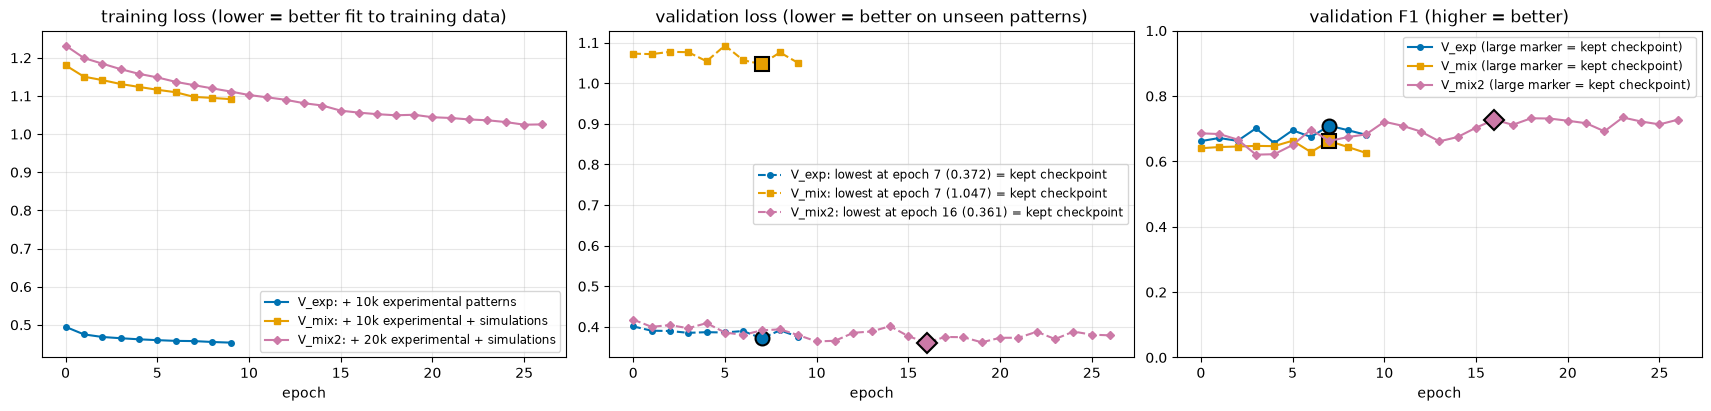

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4), constrained_layout=True)
for k in ("V_exp", "V_mix", "V_mix2"):
    col, mk = STYLE[k]
    m = pd.read_csv(next(RUNS[k].glob("logs/*/metrics.csv")))
    tr = m.dropna(subset=["train_loss"]).groupby("epoch").train_loss.last()
    v = m.dropna(subset=["val_loss"]).groupby("epoch")[["val_loss", "val_f1"]].last()
    best = int(v.val_loss.idxmin())
    axs[0].plot(tr.index, tr, color=col, marker=mk, ms=4, label=DESC[k])
    axs[1].plot(v.index, v.val_loss, color=col, marker=mk, ms=4, ls="--",
                label=f"{k}: lowest at epoch {best} ({v.val_loss.min():.3f}) = kept checkpoint")
    axs[1].plot(best, v.val_loss[best], marker=mk, ms=10, color=col, mec="black", mew=1.5, ls="none")
    axs[2].plot(v.index, v.val_f1, color=col, marker=mk, ms=4, label=f"{k} (large marker = kept checkpoint)")
    axs[2].plot(best, v.val_f1[best], marker=mk, ms=10, color=col, mec="black", mew=1.5, ls="none")
    print(f"{k}: {len(v)} epochs, train loss {tr.iloc[0]:.3f} -> {tr.iloc[-1]:.3f}, "
          f"val loss {v.val_loss.iloc[0]:.3f} -> best {v.val_loss.min():.3f} (epoch {best}) -> last {v.val_loss.iloc[-1]:.3f}, "
          f"val F1 at best epoch {v.val_f1[best]:.3f} (max {v.val_f1.max():.3f}, epoch {int(v.val_f1.idxmax())})")
axs[0].set_title("training loss (lower = better fit to training data)")
axs[1].set_title("validation loss (lower = better on unseen patterns)")
axs[2].set_title("validation F1 (higher = better)")
axs[2].set_ylim(0, 1)
for ax in axs:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8.5)
plt.show()

## 2. Thresholds

Every model uses its own detection threshold.

- **V, V_exp, V_mix**: spotiflow's `optimize_threshold` at the end of training (F1 on random crops of the validation set), from `thresholds.yaml`. V_mix also has a separate, higher threshold for **simulated** patterns (`threshold_sim.json`, section 7.4).
- **V_mix2**: its training never reached that step, so `eval_experimental.py` tuned it the same way on the **whole** validation patterns (3 val acquisitions × 500): the F1-optimal threshold in 0.30–0.70 (spotiflow's search range). It is saved to `ft_V_mix2/model/thresholds.yaml`. The simulation threshold follows `tune_sim_threshold` (lowest threshold at which V_mix2 is as precise as V); V_mix2 also trained on V's simulation validation materials, so, as `finetune_experimental.py` does in that case, the rule runs on the training simulations. Saved to `ft_V_mix2/model/threshold_sim.json`.

Left: F1 against threshold on the experimental **validation** patterns; right: the same on the **test** patterns (for reference only; nothing was chosen on test). Each model's experimental threshold is marked.

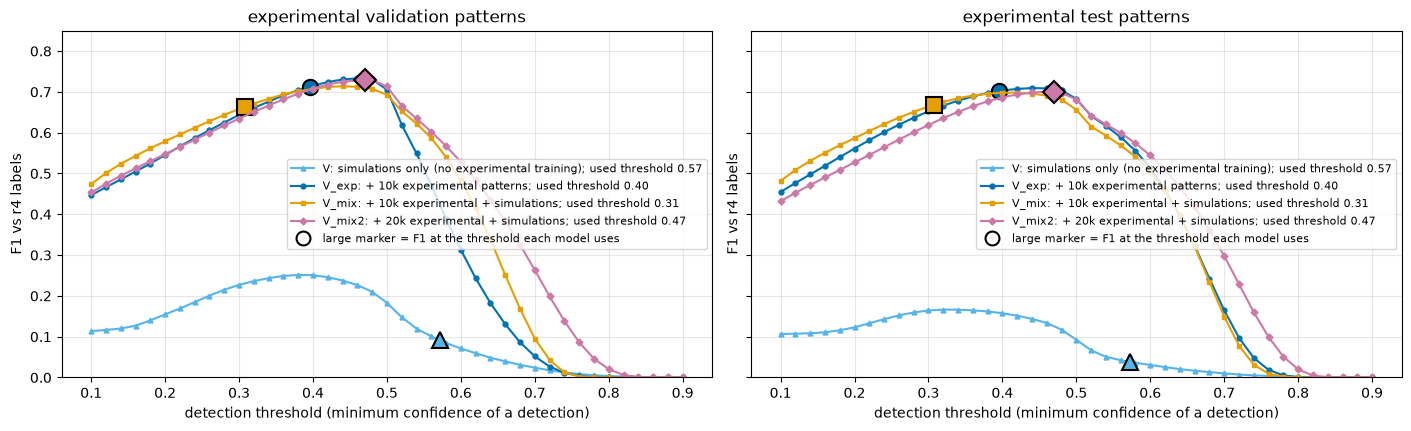

F1 at the own threshold vs the best possible threshold on test (pooled, 6 test acquisitions):
        own threshold  F1 (own)  best threshold on test  F1 (best on test)
V               0.572     0.038                    0.32              0.166
V_exp           0.396     0.702                    0.44              0.709
V_mix           0.308     0.669                    0.42              0.698
V_mix2          0.470     0.700                    0.46              0.700


In [3]:
sweep = pd.read_csv(EV / "exp_sweep.csv")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True, sharey=True)
for ax, role in zip(axs, ("val", "test")):
    for k, (col, mk) in STYLE.items():
        s = sweep[(sweep.model == k) & (sweep.split == role)]
        t = thr[k]["exp"]
        ax.plot(s.threshold, s.f1, color=col, marker=mk, ms=3.5, label=f"{DESC[k]}; used threshold {t:.2f}")
        f_at = np.interp(t, s.threshold, s.f1)
        ax.plot(t, f_at, marker=mk, ms=11, color=col, mec="black", mew=1.5, ls="none")
    ax.plot([], [], marker="o", ms=10, mfc="none", mec="black", mew=1.5, ls="none",
            label="large marker = F1 at the threshold each model uses")
    ax.set(xlabel="detection threshold (minimum confidence of a detection)", ylabel="F1 vs r4 labels", ylim=(0, 0.85),
           title=f"experimental {'validation' if role == 'val' else 'test'} patterns")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

best_test = sweep[sweep.split == "test"].loc[lambda d: d.groupby("model").f1.idxmax()].set_index("model")
print("F1 at the own threshold vs the best possible threshold on test (pooled, 6 test acquisitions):")
own = pd.read_csv(EV / "exp_test.csv").query("material == 'all'").set_index("model")
print(pd.DataFrame({"own threshold": {k: thr[k]["exp"] for k in RUNS}, "F1 (own)": own.f1.round(3),
                    "best threshold on test": best_test.threshold, "F1 (best on test)": best_test.f1.round(3)}
                   ).loc[list(RUNS)].to_string())

## 3. Test scores: experimental test acquisitions

Pooled over the 500 patterns of each test acquisition, against the r4 labels (confidence ≥ 0.8), each model at its own experimental threshold. The r4 label on the direct beam is counted as missed (as in section 7), so recall is ≈ 2 % low for every model.

Experimental test acquisitions vs r4 labels (confidence >= 0.8), 500 patterns per acquisition:
                 V                   V_exp                   V_mix                  V_mix2              
         precision recall     f1 precision recall     f1 precision recall     f1 precision recall     f1
material                                                                                                
Ag           0.308  0.000  0.001     0.669  0.491  0.567     0.578  0.532  0.554     0.729  0.389  0.507
Au           0.868  0.020  0.038     0.713  0.770  0.740     0.621  0.806  0.701     0.753  0.702  0.726
Au+Ag        0.934  0.009  0.018     0.663  0.668  0.666     0.583  0.698  0.635     0.726  0.598  0.656
CoO          0.929  0.032  0.062     0.782  0.778  0.780     0.692  0.794  0.740     0.869  0.708  0.780
Pd           0.960  0.022  0.044     0.629  0.797  0.703     0.592  0.800  0.680     0.754  0.720  0.737
ZnO          0.931  0.032  0.062     0.615  0.806  0.698     0.54

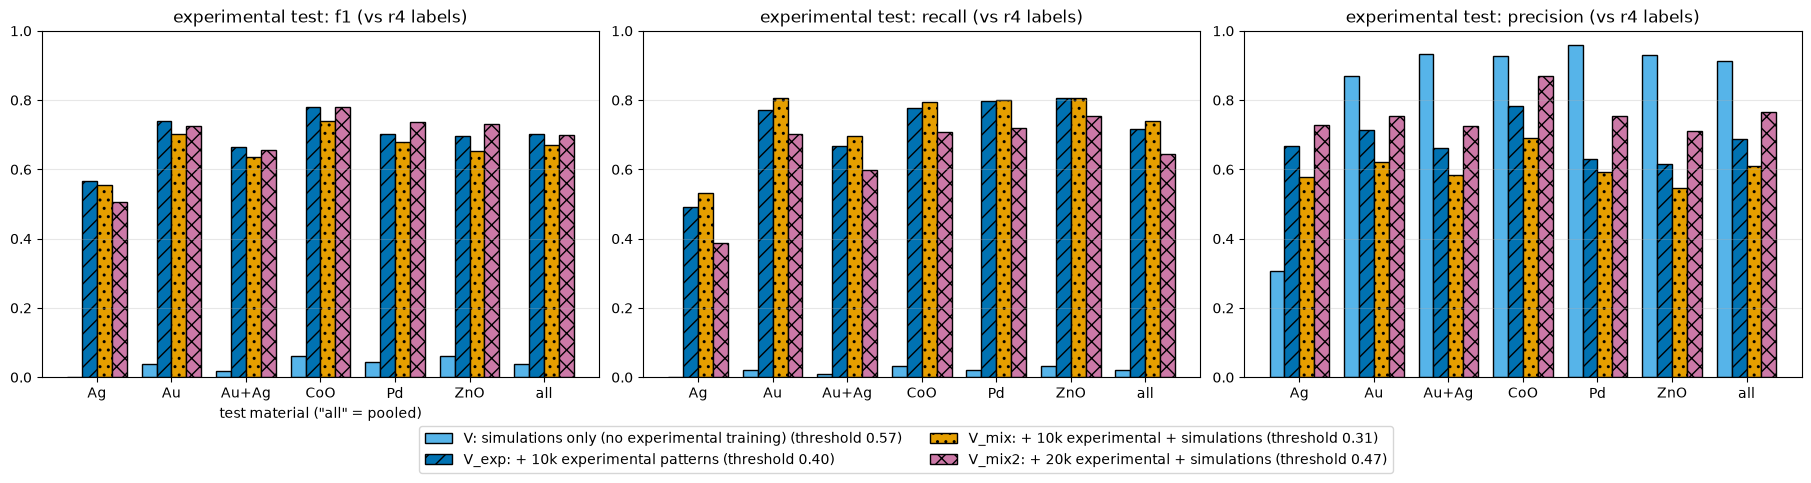

In [4]:
exp = pd.read_csv(EV / "exp_test.csv").set_index(["model", "material"])
exp6 = pd.concat({k: exp.loc[k] for k in RUNS}, axis=1)
print("Experimental test acquisitions vs r4 labels (confidence >= 0.8), 500 patterns per acquisition:")
print(exp6.loc[:, (slice(None), ["precision", "recall", "f1"])].round(3).to_string())
print("\ncounts (all materials):")
print(exp6.loc["all", (slice(None), ["tp", "n_pred", "n_label"])].unstack().astype(int).to_string())

mats = [m for m in exp6.index if m != "all"] + ["all"]
fig, axs = plt.subplots(1, 3, figsize=(18, 4.2), constrained_layout=True)
w = 0.2
for ax, metric in zip(axs, ("f1", "recall", "precision")):
    x = np.arange(len(mats))
    for i, (k, (col, mk)) in enumerate(STYLE.items()):
        vals = exp6.loc[mats, (k, metric)].values
        ax.bar(x + (i - 1.5) * w, vals, w, color=col, edgecolor="black", hatch=["", "//", "..", "xx"][i],
               label=f"{DESC[k]} (threshold {thr[k]['exp']:.2f})")
    ax.set_xticks(x, mats)
    ax.set(ylim=(0, 1), title=f"experimental test: {metric} (vs r4 labels)")
    ax.grid(alpha=0.3, axis="y")
axs[0].set_xlabel("test material (\"all\" = pooled)")
fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.13), fontsize=10)
plt.show()

## 4. Test scores: simulated test patterns

Does training on real data keep the simulations working? V's 45 simulation test patterns, pooled per angle, at two thresholds per model:

- **own**: the model's experimental threshold (what section 7.3 showed);
- **sim**: the simulation threshold (V_mix and V_mix2 have one; for V and V_exp it is the same as their own).

Simulation test materials (BW, Co3(O2F)2, SiO2; 20-500 Å):
      V own (0.57)           V_exp own (0.40)           V_mix own (0.31)           V_mix sim (0.68)           V_mix2 own (0.47)           V_mix2 sim (0.60)          
        recall_vis precision       recall_vis precision       recall_vis precision       recall_vis precision        recall_vis precision        recall_vis precision
angle                                                                                                                                                                
1.0          0.763     0.991            0.738     0.571            0.881     0.877            0.668     0.986             0.861     0.917             0.531     0.972
2.0          0.565     0.981            0.419     0.472            0.799     0.832            0.541     0.989             0.761     0.931             0.408     0.962
4.0          0.358     0.988            0.063     0.097            0.652     0.455            0.336     0.964  

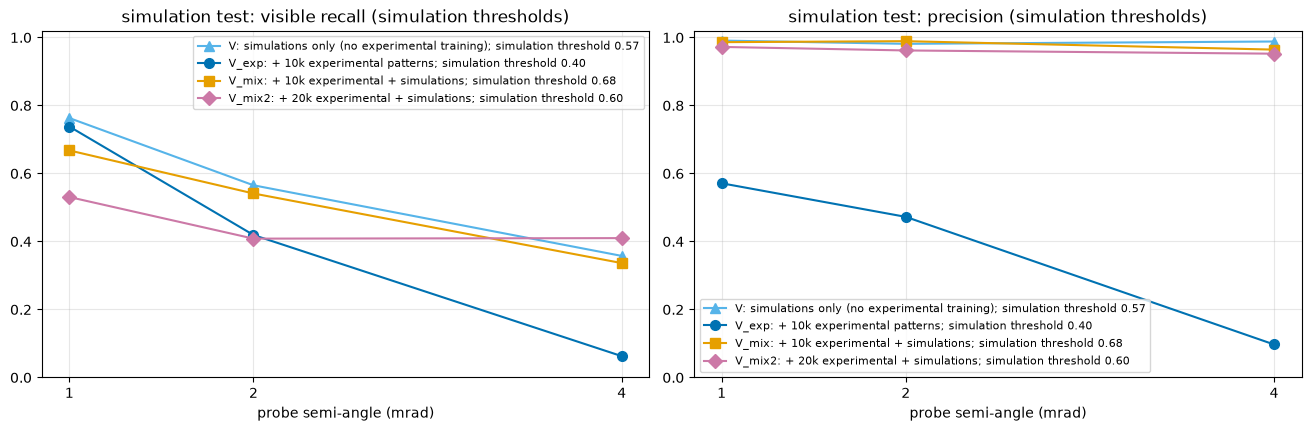

In [5]:
sim = pd.read_csv(EV / "sim_test.csv").set_index(["model", "rule", "angle"])
cols = {}
for k in RUNS:
    for rule in ("own", "sim"):
        if rule == "sim" and thr[k]["sim"] == thr[k]["exp"]:
            continue
        cols[f"{k} {rule} ({thr[k]['exp' if rule == 'own' else 'sim']:.2f})"] = sim.loc[(k, rule)]
sim6 = pd.concat(cols, axis=1)
print("Simulation test materials (BW, Co3(O2F)2, SiO2; 20-500 Å):")
print(sim6.loc[:, (slice(None), ["recall_vis", "precision"])].round(3).to_string())
print("\nfalse / truly false detections:")
print(sim6.loc[:, (slice(None), ["false", "truly_false"])].astype(int).to_string())

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
for k, (col, mk) in STYLE.items():
    rule = "sim"
    s = sim.loc[(k, rule)]
    lab = f"{DESC[k]}; simulation threshold {thr[k]['sim']:.2f}"
    axs[0].plot(s.index, s.recall_vis, color=col, marker=mk, ms=7, label=lab)
    axs[1].plot(s.index, s.precision, color=col, marker=mk, ms=7, label=lab)
for ax, t in zip(axs, ("visible recall", "precision")):
    ax.set(xlabel="probe semi-angle (mrad)", xticks=[1, 2, 4], ylim=(0, 1.02),
           title=f"simulation test: {t} (simulation thresholds)")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

## 5. Predictions on experimental test patterns

One pattern per test acquisition (the middle of the scan, pattern 2500), one row per material. Left: the model input `log1p(img / max × 1000)`. Then V, V_exp, V_mix and V_mix2 at their own experimental thresholds. The r4 label on the direct beam is not drawn or counted here.

| marker | meaning |
|---|---|
| ○ light blue | found: prediction within 3 px of an r4 label |
| ✕ orange | missed r4 label |
| △ yellow | prediction with no r4 label within 3 px (a false detection, or a faint disk r4 left out) |
| + pink | direct beam |

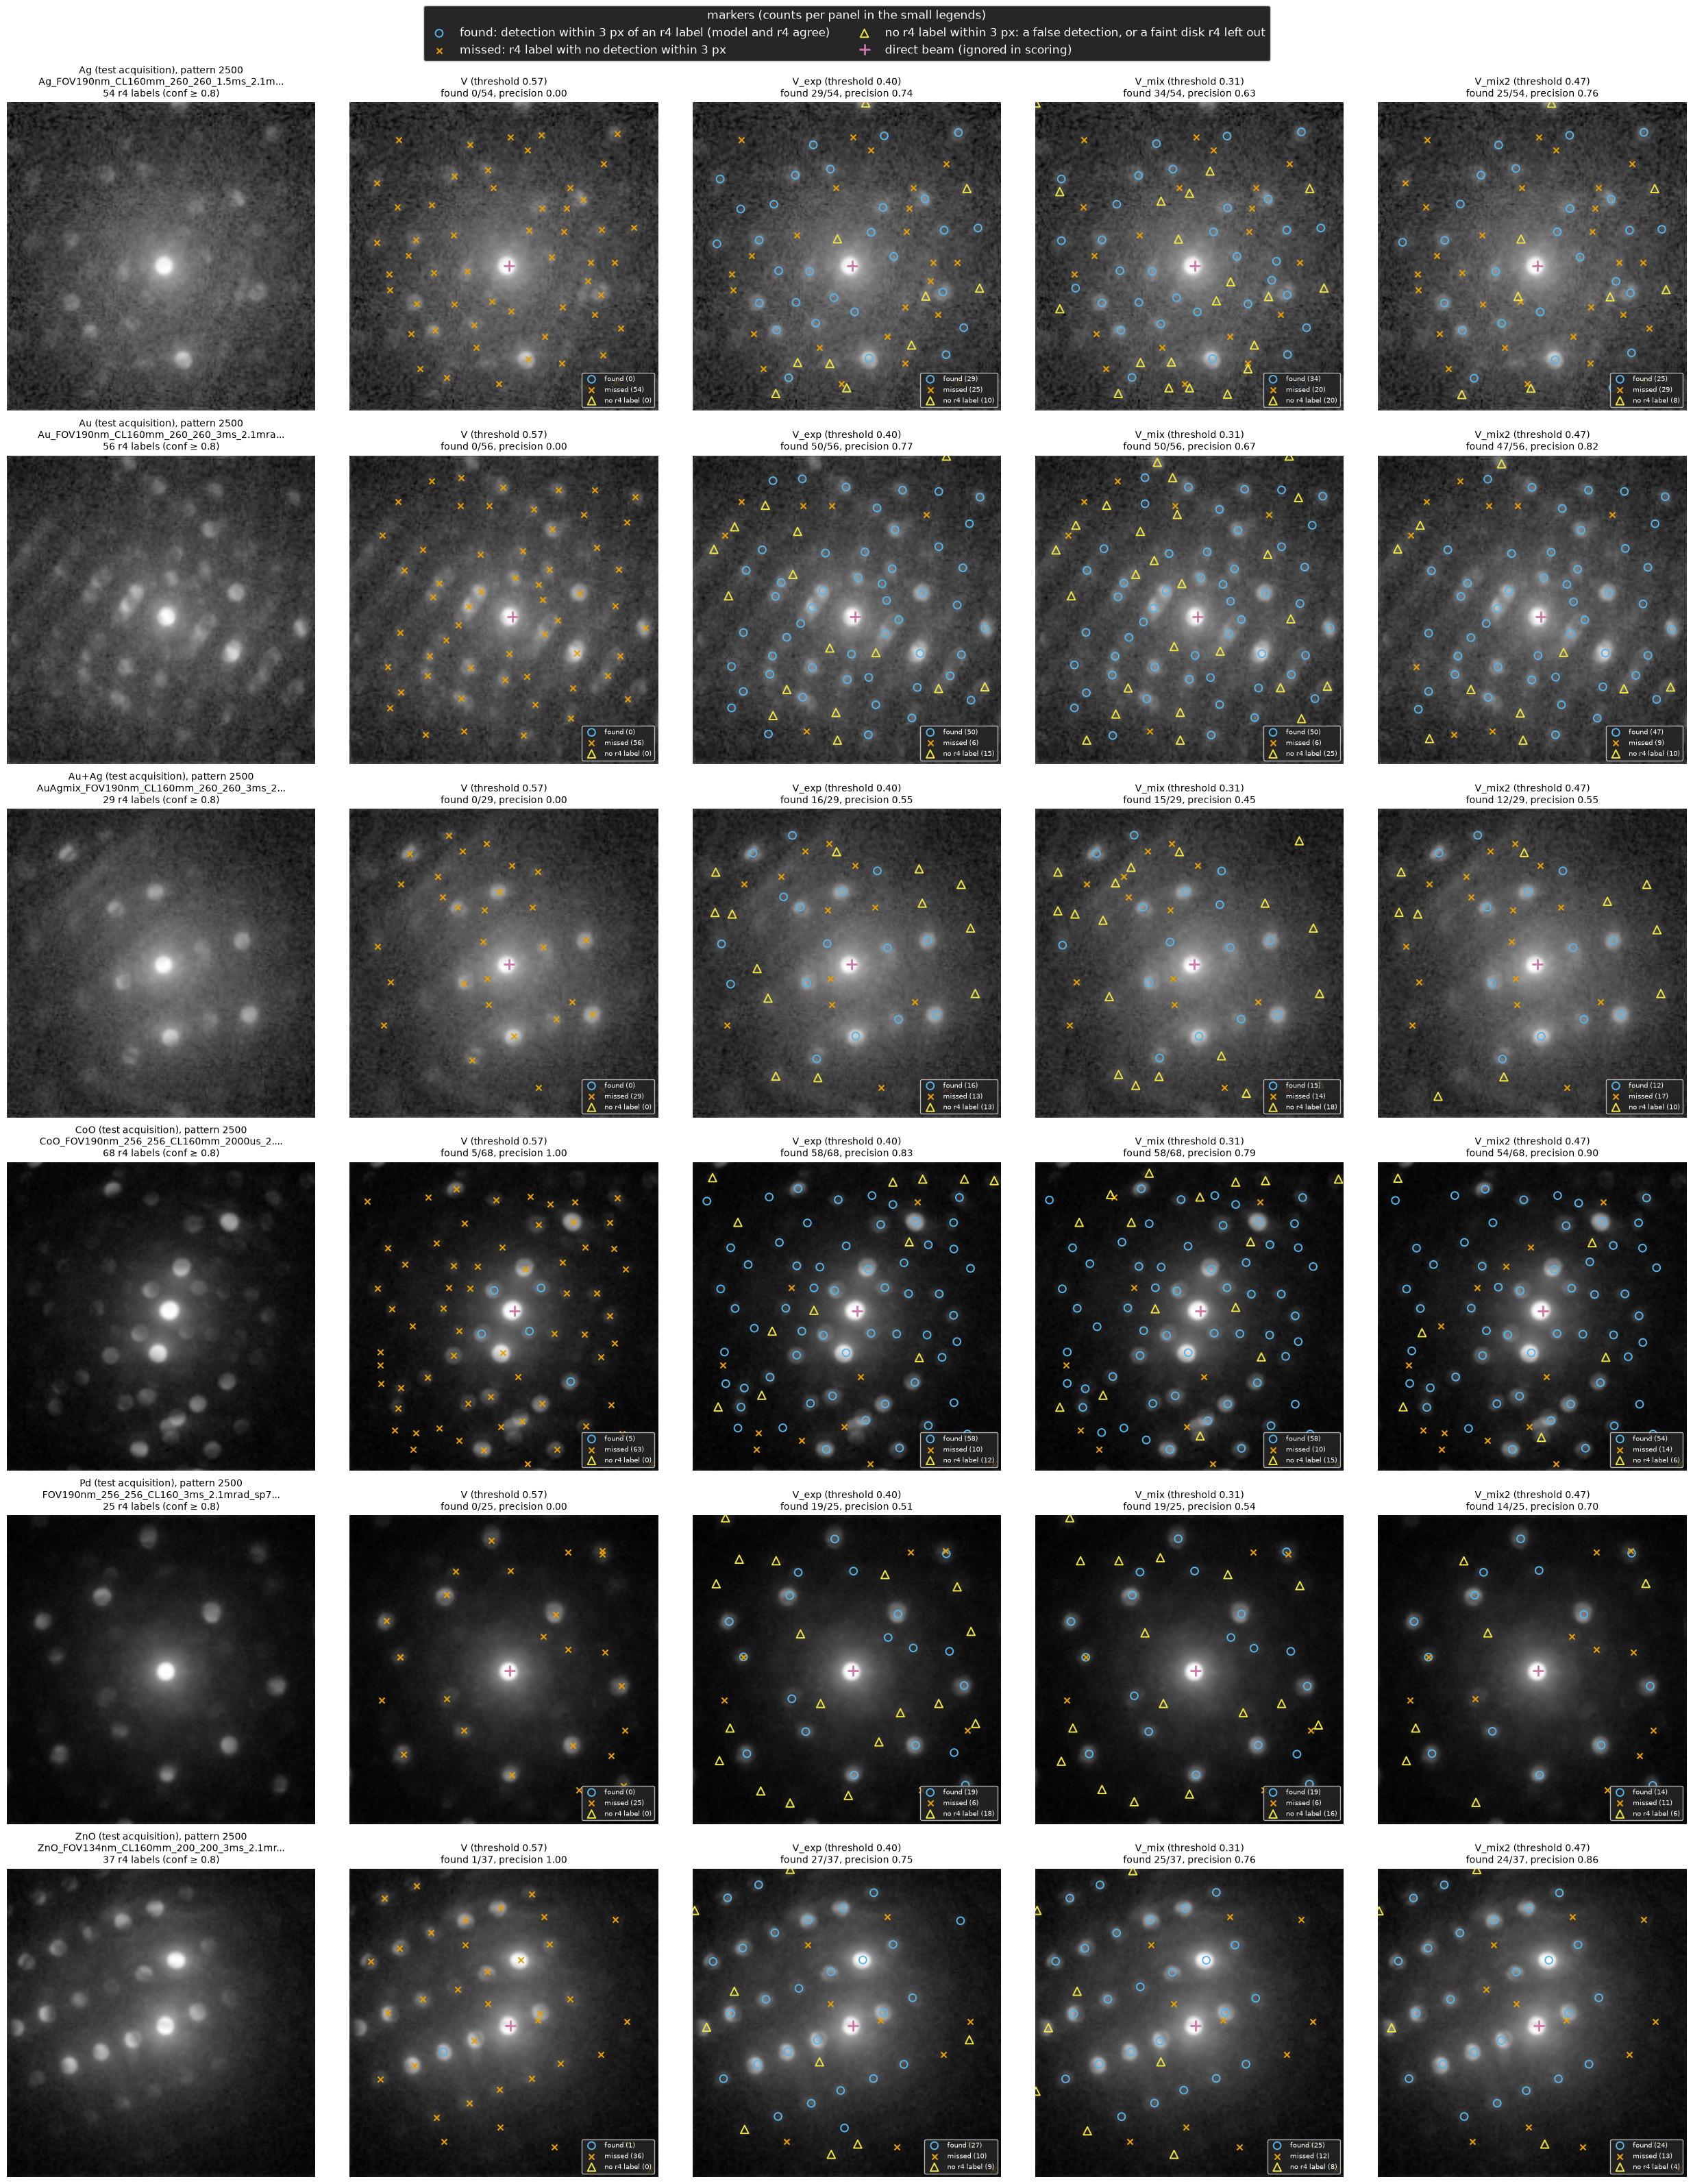

In [6]:
MODELS = {k: Spotiflow.from_folder(str(d / "model"), map_location="cuda") for k, d in RUNS.items()}
for k, m in MODELS.items():
    assert abs(m._prob_thresh[0] - thr[k]["exp"]) < 1e-6, f"{k}: loaded threshold differs from thresholds.json"

MARK7 = [("found", "found", "found: detection within 3 px of an r4 label (model and r4 agree)",
          dict(s=60, marker="o", facecolors="none", edgecolors=SKY, linewidths=1.4)),
         ("missed", "missed", "missed: r4 label with no detection within 3 px",
          dict(s=34, marker="x", c=ORANGE, linewidths=1.5)),
         ("extra", "no r4 label", "no r4 label within 3 px: a false detection, or a faint disk r4 left out",
          dict(s=70, marker="^", facecolors="none", edgecolors=YELLOW, linewidths=1.4))]


def exp_pattern(acq, n=2500, min_conf=0.8):
    with h5py.File(EXP_DATA / f"{acq}.h5", "r") as h:
        off = h["point_offsets"][:]
        img, beam = h["images"][n], h["beam"][n]
        pts, conf = h["points"][off[n]:off[n + 1]], h["confidence"][off[n]:off[n + 1]]
        material = str(h.attrs["material"])
    lab = pts[(conf >= min_conf) & off_beam(pts, beam)]
    return material, np.log1p(img / img.max() * 1000).astype(np.float32), lab, beam


def exp_categories(lab, pred, beam):
    pred = np.asarray(pred, float).reshape(-1, 2)
    pred = pred[off_beam(pred, beam)] if len(pred) else pred
    m = points_matching(lab, pred, cutoff_distance=CUTOFF)
    pj = [b for _, b in m.matched_pairs]
    return dict(found=pred[pj].reshape(-1, 2), missed=lab[sorted(m.false_negatives)].reshape(-1, 2),
                extra=pred[sorted(m.false_positives)].reshape(-1, 2))


test_acqs = sorted(exp_split["test"], key=lambda a: exp_split["materials"][a])
fig, axs = plt.subplots(len(test_acqs), 1 + len(MODELS), figsize=(25, 5.3 * len(test_acqs)), layout="constrained")
key_handles = [plt.scatter([], [], **style) for *_, style in MARK7] + [plt.Line2D([], [], marker="+", c=PINK, ms=12, mew=2, ls="none")]
key_labels = [long for _, _, long, _ in MARK7] + ["direct beam (ignored in scoring)"]
fig.legend(key_handles, key_labels, loc="outside upper center", ncol=2, fontsize=12, title="markers (counts per panel in the small legends)",
           title_fontsize=12, facecolor="0.15", labelcolor="white", framealpha=1).get_title().set_color("white")
for row, acq in zip(axs, test_acqs):
    material, x, lab, beam = exp_pattern(acq)
    row[0].imshow(x, cmap=GRAY)
    row[0].set_title(f"{material} (test acquisition), pattern 2500\n{acq[:38]}...\n{len(lab)} r4 labels (conf ≥ 0.8)",
                     fontsize=10)
    for ax, (name, model) in zip(row[1:], MODELS.items()):
        pred, _ = model.predict(x, min_distance=3, subpix=True, verbose=False, device="cuda")
        cat = exp_categories(lab, pred, beam)
        n_pred = len(cat["found"]) + len(cat["extra"])
        ax.imshow(x, cmap=GRAY)
        for key, short, _, style in MARK7:
            ax.scatter(cat[key][:, 1], cat[key][:, 0], label=f"{short} ({len(cat[key])})", **style)
        ax.plot(beam[1], beam[0], "+", c=PINK, ms=12, mew=2, ls="none")
        ax.set_title(f"{name} (threshold {model._prob_thresh[0]:.2f})\nfound {len(cat['found'])}/{len(lab)}, "
                     f"precision {len(cat['found']) / max(n_pred, 1):.2f}", fontsize=10)
        ax.legend(loc="lower right", fontsize=7.5, facecolor="0.15", labelcolor="white", framealpha=0.85)
    for ax in row:
        ax.axis("off")
plt.show()

## 6. Predictions on simulated test patterns

BW (a test material) at 1, 2 and 4 mrad, 40 Å. Left: `dataMeas` (true log). Then V, V_exp, V_mix and V_mix2, all with the log ×1000 input, each at its **simulation** threshold (V_mix 0.68 and V_mix2 its own value from section 2; V and V_exp have only one threshold). Markers as in section 3 of `5_diffraction_finetune.ipynb`:

| marker | meaning |
|---|---|
| ○ light blue | found, visible |
| ◇ white | found, not visible |
| ✕ orange | missed, visible |
| ⬡ light blue, dashed | false, near a real spot (a missed candidate 3–5 px away) |
| □ orange | false, on a weaker 1–2 % `dataPots` peak |
| △ yellow | false, truly false |

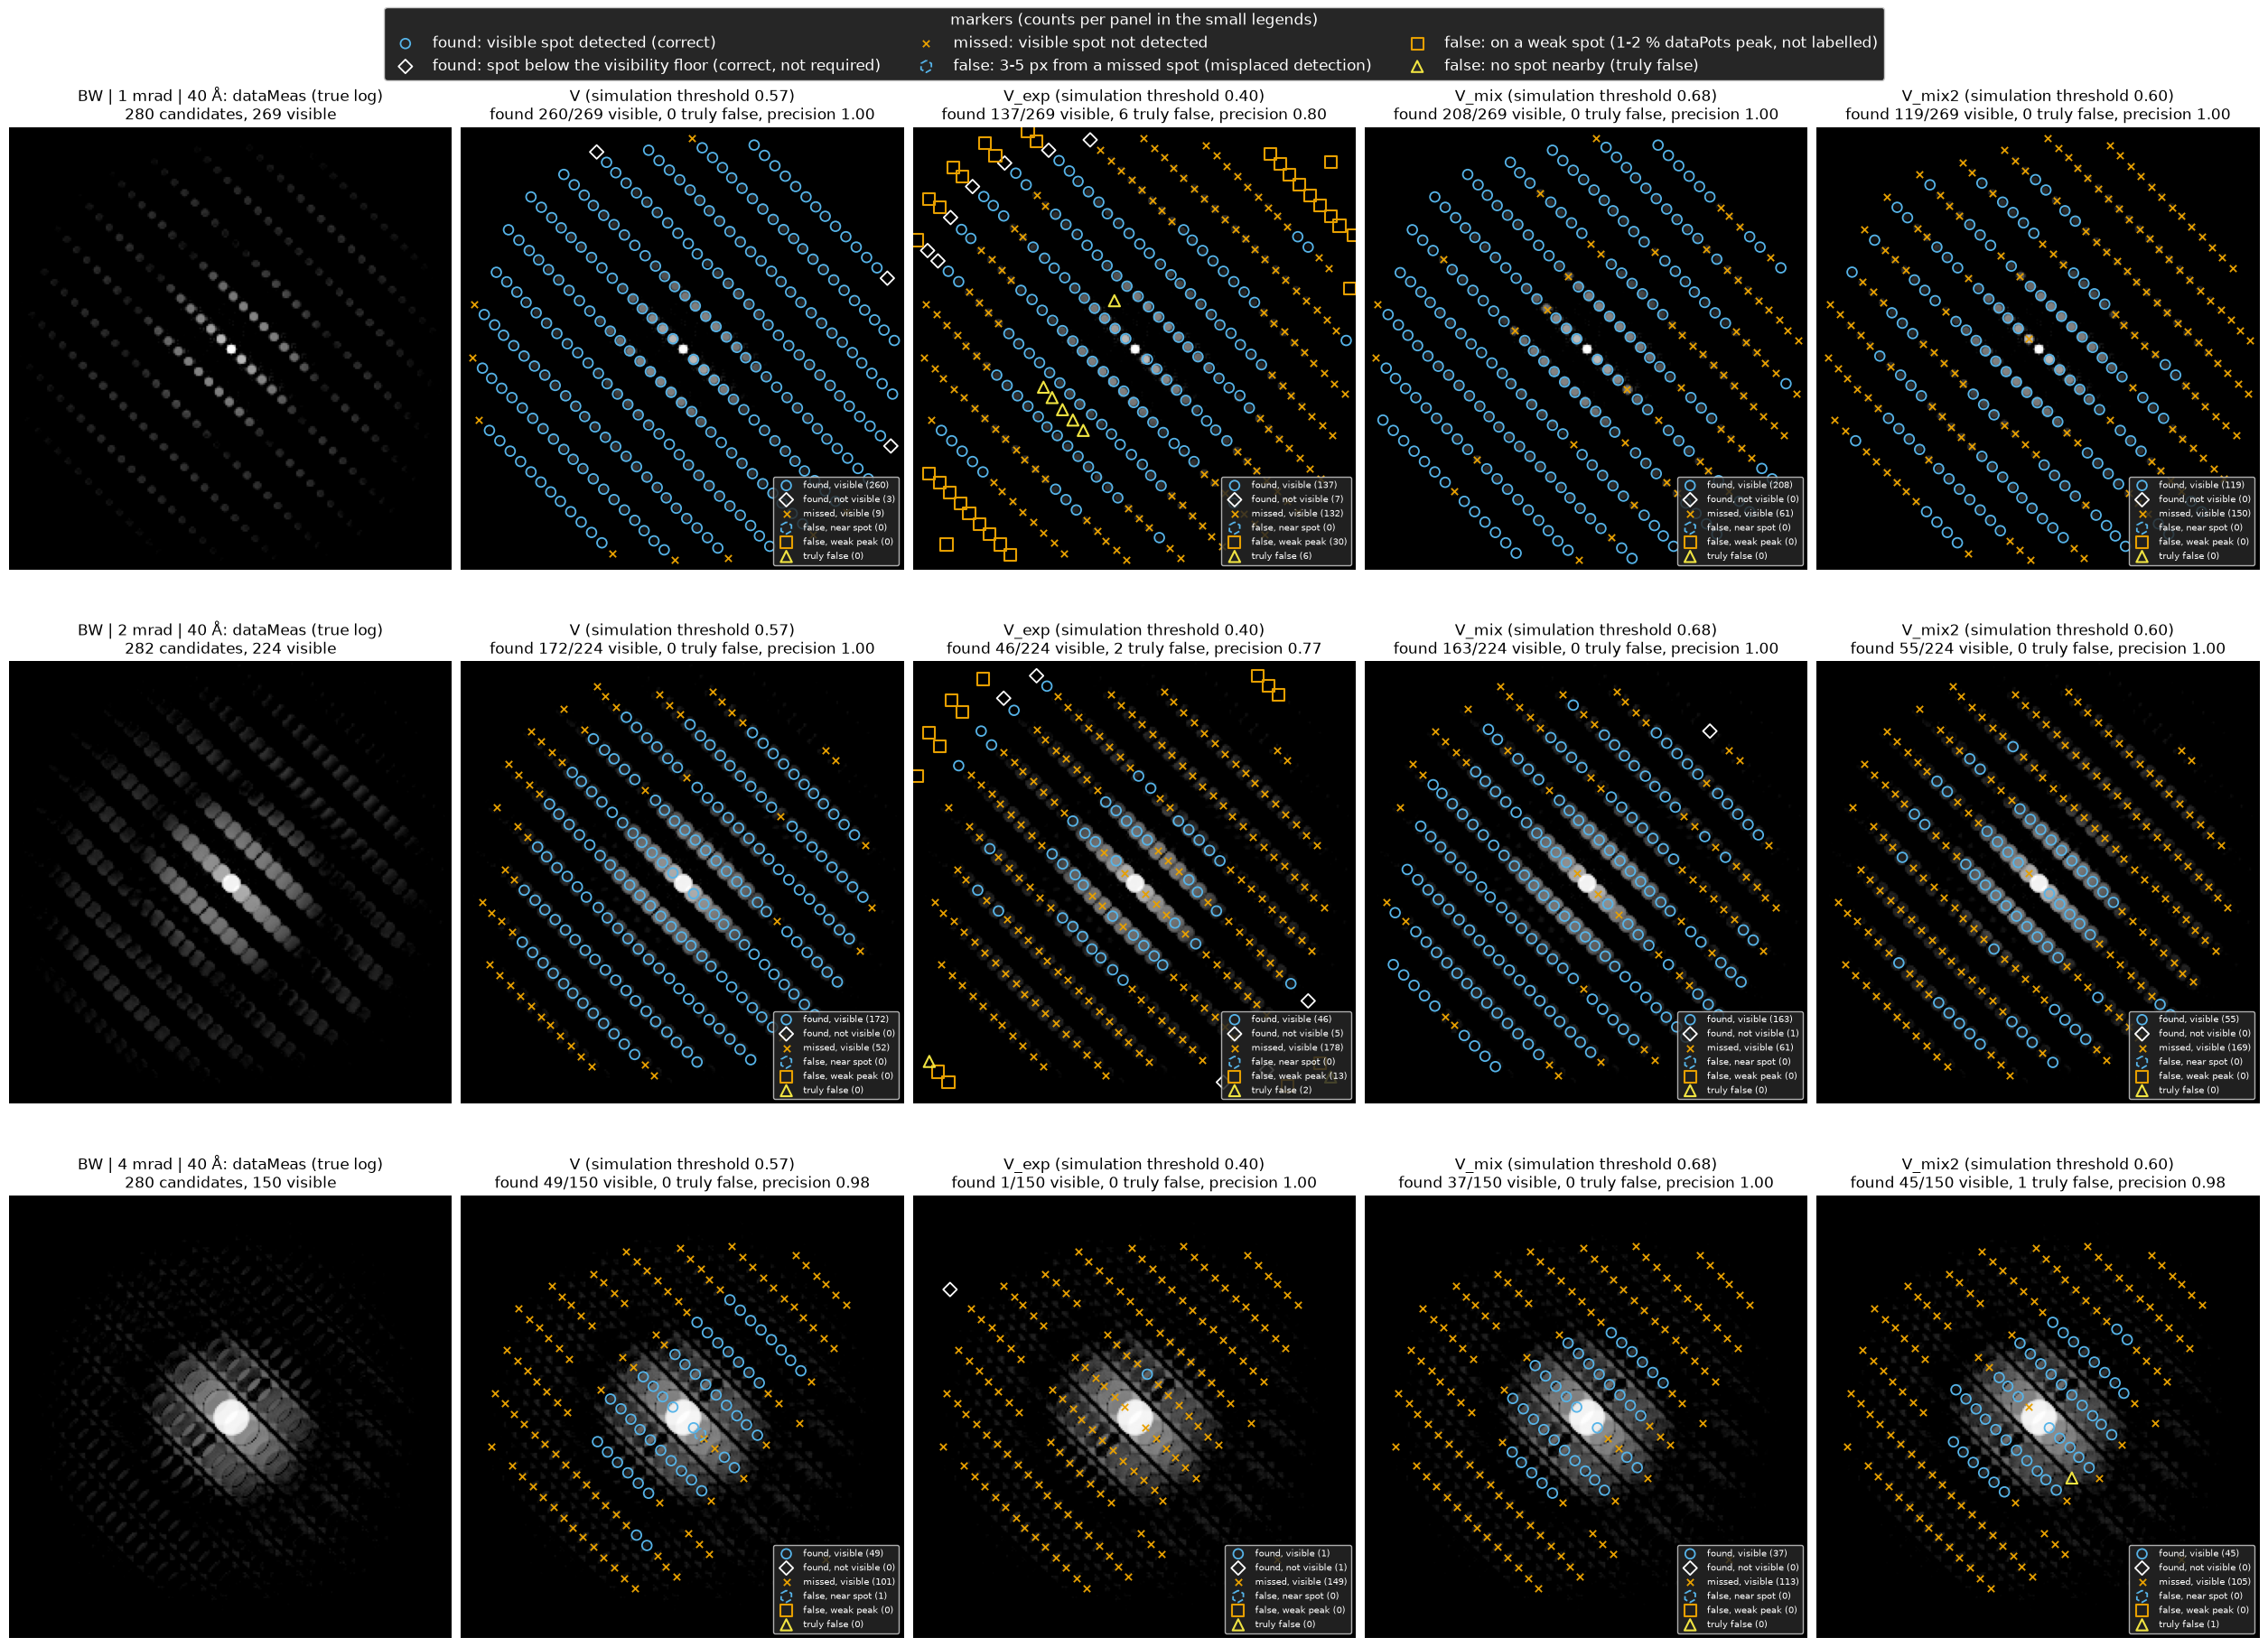

In [7]:
MARK = [
    ("found_vis", "found, visible", "found: visible spot detected (correct)", dict(s=60, marker="o", facecolors="none", edgecolors=SKY, linewidths=1.3)),
    ("found_inv", "found, not visible", "found: spot below the visibility floor (correct, not required)", dict(s=60, marker="D", facecolors="none", edgecolors="white", linewidths=1.3)),
    ("missed_vis", "missed, visible", "missed: visible spot not detected", dict(s=28, marker="x", c=ORANGE, linewidths=1.3)),
    ("fp_near", "false, near spot", "false: 3-5 px from a missed spot (misplaced detection)", dict(s=90, marker="h", facecolors="none", edgecolors=SKY, linewidths=1.3, linestyles="--")),
    ("fp_weak", "false, weak peak", "false: on a weak spot (1-2 % dataPots peak, not labelled)", dict(s=90, marker="s", facecolors="none", edgecolors=ORANGE, linewidths=1.5)),
    ("fp_false", "truly false", "false: no spot nearby (truly false)", dict(s=80, marker="^", facecolors="none", edgecolors=YELLOW, linewidths=1.5)),
]


def categories(g, pred):
    # positions of each scoring category; the same matching steps as bd.score (5_diffraction_finetune.ipynb, section 3)
    pts, vis = g["points"], g["visible"]
    pred = np.asarray(pred, float).reshape(-1, 2)
    pred = pred[bd.far_from(pred, g["beam"], bd.BEAM_R)]
    m = points_matching(pts, pred, cutoff_distance=bd.CUTOFF)
    gi = np.array([a for a, _ in m.matched_pairs], dtype=int)
    pj = np.array([b for _, b in m.matched_pairs], dtype=int)
    fp = np.array(sorted(m.false_positives), dtype=int)
    fn = np.array(sorted(m.false_negatives), dtype=int)
    m_off = points_matching(pts[fn].reshape(-1, 2), pred[fp].reshape(-1, 2), cutoff_distance=bd.NEAR_R)
    near = fp[[b for _, b in m_off.matched_pairs]] if len(fp) else fp
    rest = fp[sorted(m_off.false_positives)] if len(fp) else fp
    m_weak = points_matching(g["weak"].reshape(-1, 2).astype(float), pred[rest].reshape(-1, 2), cutoff_distance=bd.CUTOFF)
    weak = rest[[b for _, b in m_weak.matched_pairs]] if len(rest) else rest
    false = rest[sorted(m_weak.false_positives)] if len(rest) else rest
    vis_gi = vis[gi] if len(gi) else np.zeros(0, bool)
    return dict(found_vis=pred[pj[vis_gi]] if len(pj) else pred[:0], found_inv=pred[pj[~vis_gi]] if len(pj) else pred[:0],
                missed_vis=pts[fn[vis[fn]]] if len(fn) else pts[:0],
                fp_near=pred[near], fp_weak=pred[weak], fp_false=pred[false])


CASES = [("BW", 1, 40), ("BW", 2, 40), ("BW", 4, 40)]
fig, axs = plt.subplots(len(CASES), 1 + len(MODELS), figsize=(25, 6.2 * len(CASES)), layout="constrained")
fig.legend([plt.scatter([], [], **style) for *_, style in MARK], [long for _, _, long, _ in MARK],
           loc="outside upper center", ncol=3, fontsize=12, title="markers (counts per panel in the small legends)",
           title_fontsize=12, facecolor="0.15", labelcolor="white", framealpha=1).get_title().set_color("white")
for row, (material, angle, thickness) in zip(axs, CASES):
    img, gt, probe = load_slice(material, angle, thickness)
    g = bd.ground_truth(img, gt, disk_radius(probe), VIS_BOX)
    x = bd.spotiflow_input(img, probe, "log", log_scale=1000).astype(np.float32)
    norm_ = LogNorm(vmin=g["floor"], vmax=img.max())
    row[0].imshow(img, cmap=GRAY, norm=norm_)
    row[0].set_title(f"{material} | {angle} mrad | {thickness} Å: dataMeas (true log)\n"
                     f"{len(g['points'])} candidates, {int(g['visible'].sum())} visible")
    for ax, (name, model) in zip(row[1:], MODELS.items()):
        t = thr[name]["sim"]
        pred, _ = model.predict(x, prob_thresh=t, min_distance=3, subpix=True, verbose=False, device="cuda")
        s = bd.score(g, pred)
        cat = categories(g, pred)
        assert len(cat["found_vis"]) == s["found_vis"] and len(cat["fp_false"]) == s["truly_false"]
        ax.imshow(img, cmap=GRAY, norm=norm_)
        for key, short, _, style in MARK:
            ax.scatter(cat[key][:, 1], cat[key][:, 0], label=f"{short} ({len(cat[key])})", **style)
        ax.set_title(f"{name} (simulation threshold {t:.2f})\nfound {s['found_vis']}/{s['n_vis']} visible, "
                     f"{s['truly_false']} truly false, precision {s['precision']:.2f}")
        ax.legend(loc="lower right", fontsize=7.5, facecolor="0.15", labelcolor="white", framealpha=0.85)
    for ax in row:
        ax.axis("off")
plt.show()

### Results

**Loss (section 1).** V_mix2 trained 27 of 30 epochs. Training loss fell the whole time (1.232 → 1.025). Validation loss reached its minimum at **epoch 16** (0.361, the kept `best.pt`), then varied between 0.36 and 0.39 without improving. Validation F1 went from 0.69 at epoch 0 to ≈ 0.72–0.73 from epoch 16 on (0.728 at the kept epoch, max 0.734 at epoch 23). The last 3 epochs would most likely not have changed the result.

**Thresholds (section 2).** V_mix2: **0.47** for experimental patterns (validation F1 0.729) and **0.60** for simulated ones. On the test patterns the F1 curves of V_exp, V_mix and V_mix2 peak at almost the same height (0.709 / 0.698 / 0.700). V_mix2's threshold lies on its test optimum (0.46). V_mix's 0.31 is too low (test optimum 0.42), which costs it 0.03 F1. V_mix2's curve is also flatter above 0.5, so its result depends less on the exact threshold.

**Experimental test (section 3)**, 3000 patterns, own thresholds:

| | V | V_exp | V_mix | V_mix2 |
|---|---|---|---|---|
| F1 (all 6 materials) | 0.04 | **0.702** | 0.669 | **0.700** |
| precision / recall | 0.91 / 0.02 | 0.69 / 0.72 | 0.61 / 0.74 | **0.77** / 0.64 |
| predictions (labels: 147 526) | 3 172 | 153 720 | 178 704 | 123 742 |

- **Twice the experimental data and 3× the epochs did not raise F1**: V_mix2 equals V_exp (0.700 vs 0.702) and is 0.03 above V_mix. It **trades recall for precision**: about 30 000 fewer predictions than V_exp, with 10 % fewer hits.
- By material, V_mix2 is the best model on Pd (0.737) and ZnO (0.732), equal on CoO (0.780), and worst on **Ag** (0.507: recall 0.39). In the overlays (section 5) it misses the faint outer disks that V_exp and V_mix still find, but also leaves out most of the "no label" detections on background.

**Simulation test (section 4).**

| visible recall / precision | 1 mrad | 2 mrad | 4 mrad |
|---|---|---|---|
| V (0.57) | 0.76 / 0.99 | 0.57 / 0.98 | 0.36 / 0.99 |
| V_mix own (0.31) | 0.88 / 0.88 | 0.80 / 0.83 | 0.65 / 0.46 |
| V_mix sim (0.68) | 0.67 / 0.99 | 0.54 / 0.99 | 0.34 / 0.96 |
| V_mix2 own (0.47) | 0.86 / 0.92 | 0.76 / 0.93 | 0.59 / 0.81 |
| V_mix2 sim (0.60) | 0.53 / 0.97 | 0.41 / 0.96 | 0.41 / 0.95 |

- At its **experimental** threshold, V_mix2 is clearly more precise on simulations than V_mix at its own: at 4 mrad 320 false detections (181 truly false) against V_mix's 1808 (1442). So a single threshold of 0.47 for both kinds of data is usable, unlike V_mix's 0.31.
- At the **simulation** threshold 0.60, V_mix2 is as precise as V but finds fewer visible spots at 1 and 2 mrad (0.53 / 0.41 vs 0.76 / 0.57; BW 40 Å in section 6: 119/269 and 55/224 vs V's 260/269 and 172/224). Only at 4 mrad does it beat V (0.41 vs 0.36). As for V_mix in section 7.4: **at equal precision, the mixed models are not better than V on simulations**.
- The 0.60 rule was tuned on the *training* simulations (V_mix2 also trained on V's simulation validation materials), where V_mix2 is more confident than on unseen materials. That may be why it removes so much recall on the test materials.

**Conclusion.**
- For **experimental** patterns, V_exp and V_mix2 are equally good (F1 0.70). Choose V_mix2 if precision matters more than recall (0.77 vs 0.69), V_exp for more found disks.
- For **one model on both kinds of data**, V_mix2 at a single threshold of 0.47 is the best compromise so far: experimental F1 0.70 (V_mix 0.67), and simulation precision 0.81–0.93 (V_mix at 0.31: 0.46–0.88).
- More data and epochs mainly changed the confidence scale, not the ranking. The open problems are the same as in section 7: faint disks (Ag), and the r4 labels themselves (the direct beam label counts as missed, and faint disks r4 left out count as false).

## 7. How much of the "error" is in the r4 labels?

The experimental scores compare predictions with r4 disks of confidence ≥ 0.8. r4 is the dataset authors' detector,
not ground truth, so part of the "errors" may be label errors. Written by `check_exp_labels.py` (same 6 test
acquisitions × 500 patterns, each model at its own threshold) into `diffraction_runs/eval_exp/labels_check/`.

Four scorings:

| scoring | reference |
|---|---|
| `current` | r4 ≥ 0.8, direct-beam label kept (= sections 3 and 5) |
| `no_beam` | r4 ≥ 0.8, direct-beam label removed. r4 lists the beam as a disk in 99.9 % of patterns, but predictions on the beam are ignored, so this label was always a miss |
| `all_r4` | every r4 disk (score > 0.5), beam removed |
| `lenient` | r4 ≥ 0.8 must be found; r4 0.5–0.8 are optional (a hit on one is not a false positive, a miss is not a miss) |

In [2]:
LC = EV / "labels_check"
sc = pd.read_csv(LC / "scores.csv").set_index(["model", "scoring", "material"])
tab = sc.xs("all", level="material")[["threshold", "precision", "recall", "f1"]].unstack("scoring")
order = ["current", "no_beam", "all_r4", "lenient"]
display(pd.concat({m: tab[m][order] for m in ("precision", "recall", "f1")}, axis=1).round(3))
print("V_mix2, lenient scoring, per material:")
display(sc.loc[("V_mix2", "lenient")][["precision", "recall", "f1"]].round(3))

precision                         recall                         \
scoring   current no_beam all_r4 lenient current no_beam all_r4 lenient   
model                                                                     
V_exp       0.688   0.688  0.717   0.708   0.717   0.734  0.685   0.734   
V_mix       0.611   0.611  0.638   0.628   0.740   0.757  0.708   0.757   
V_mix2      0.767   0.767  0.790   0.785   0.643   0.658  0.608   0.658   

             f1                         
scoring current no_beam all_r4 lenient  
model                                   
V_exp     0.702   0.710  0.701   0.721  
V_mix     0.669   0.676  0.671   0.686  
V_mix2    0.700   0.708  0.687   0.716

V_mix2, lenient scoring, per material:


/tmp/ipykernel_335604/4126352545.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  display(sc.loc[("V_mix2", "lenient")][["precision", "recall", "f1"]].round(3))


,precision,recall,f1
material,,,
Ag,0.745,0.397,0.518
Au,0.768,0.715,0.740
Au+Ag,0.744,0.614,0.672
CoO,0.880,0.718,0.791
Pd,0.782,0.743,0.762
ZnO,0.737,0.779,0.757
all,0.785,0.658,0.716


**Contrast of the detections.** For every off-beam V_mix2 detection the local contrast is measured on the raw counts:
`snr = (mean within 2 px − median of the 5–8 px ring) / robust std of the ring`. It is compared with r4 ≥ 0.8 disks the
model missed, and with random background positions (≥ 8 px from every disk and detection). `edge` is the share of
points within 4 px of the pattern border. Caveat: detections sit on local maxima, so their snr is biased upwards
compared with random background positions.

above_background = snr above the 95th percentile of background positions (0.80)


,n,median_snr,above_background,edge,share_of_detections
group,,,,,
"detected, r4 >= 0.8",94901,4.025,0.996,0.003,0.767
"detected, r4 0.5-0.8",2900,2.258,0.989,0.061,0.023
"detected, no r4 label",25941,2.145,0.987,0.113,0.210
missed r4 >= 0.8,49309,0.834,0.522,0.010,NaN
background,30000,-0.054,0.050,0.001,NaN


cat,r4 >= 0.8,r4 0.5-0.8,no r4 label
material,,,
Ag,0.729,0.021,0.250
Au,0.753,0.019,0.228
Au+Ag,0.726,0.023,0.250
CoO,0.869,0.012,0.119
Pd,0.754,0.036,0.210
ZnO,0.710,0.037,0.253


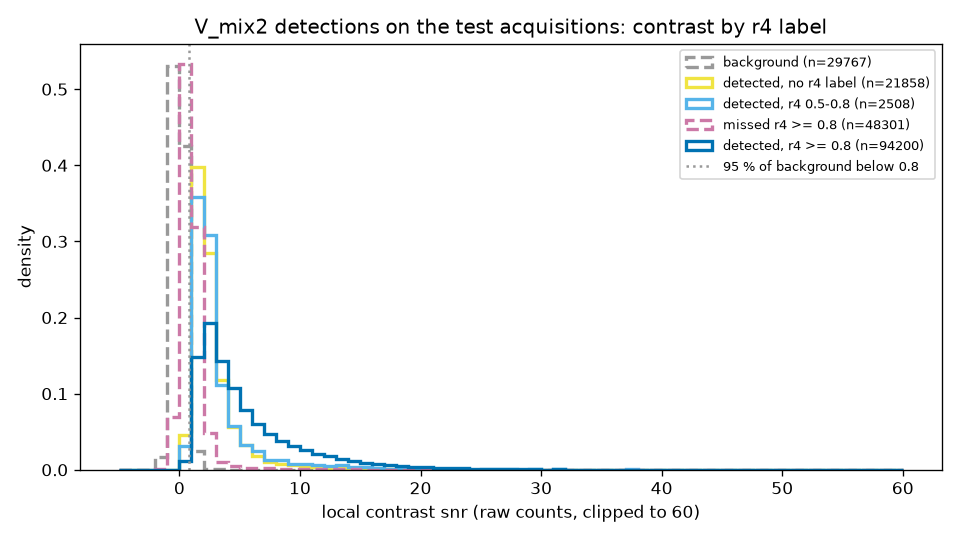

In [3]:
det = pd.read_csv(LC / "detections.csv")
bg95 = det.loc[det.group == "background", "snr"].quantile(0.95)
groups = ["detected, r4 >= 0.8", "detected, r4 0.5-0.8", "detected, no r4 label", "missed r4 >= 0.8", "background"]
summ = det.groupby("group").agg(n=("snr", "size"), median_snr=("snr", "median"),
                                above_background=("snr", lambda s: (s.dropna() > bg95).mean()),
                                edge=("edge", "mean")).loc[groups]
summ["share_of_detections"] = summ.n / summ.n[groups[:3]].sum()
summ.loc[groups[3:], "share_of_detections"] = np.nan
print(f"above_background = snr above the 95th percentile of background positions ({bg95:.2f})")
display(summ.round(3))
display(det[det.kind == "pred"].groupby("material").cat.value_counts(normalize=True).unstack()[
    ["r4 >= 0.8", "r4 0.5-0.8", "no r4 label"]].round(3))

from IPython.display import Image, display as show
show(Image(str(LC / "snr_hist.png")))

**Eye check.** 48 random crops (33 × 33 px, log scale) of each group. Yellow +: the point; sky circle: r4 ≥ 0.8;
orange square: r4 0.5–0.8. Black areas are outside the pattern (image edge).

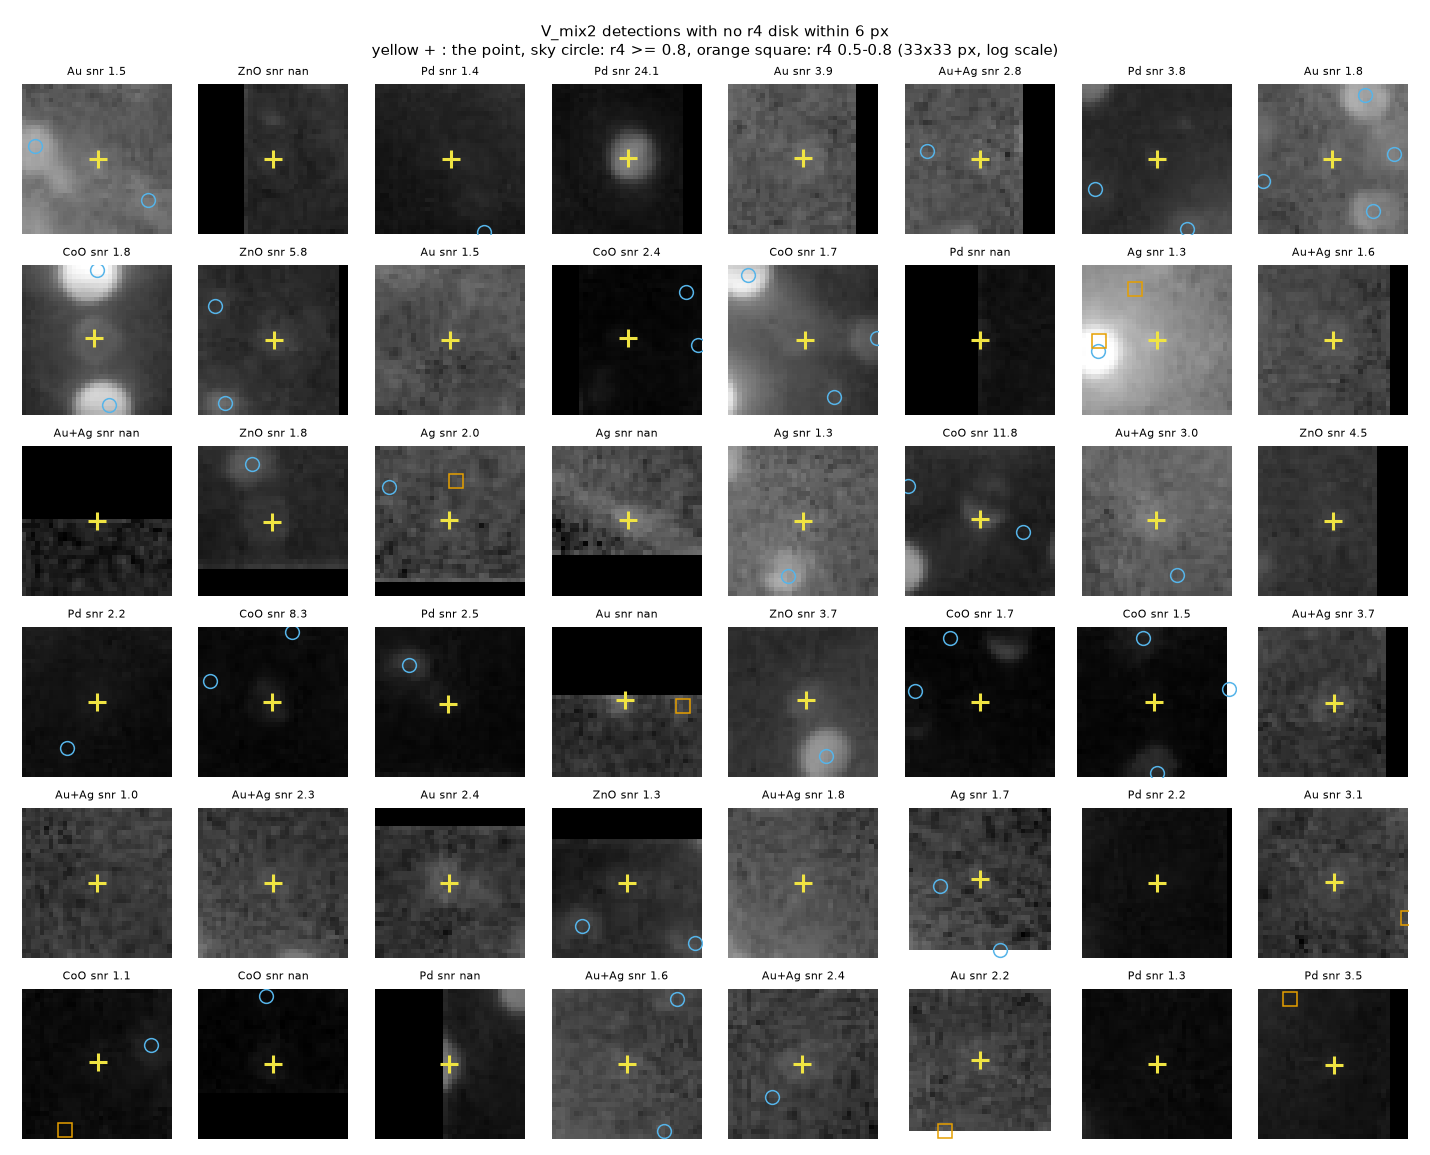

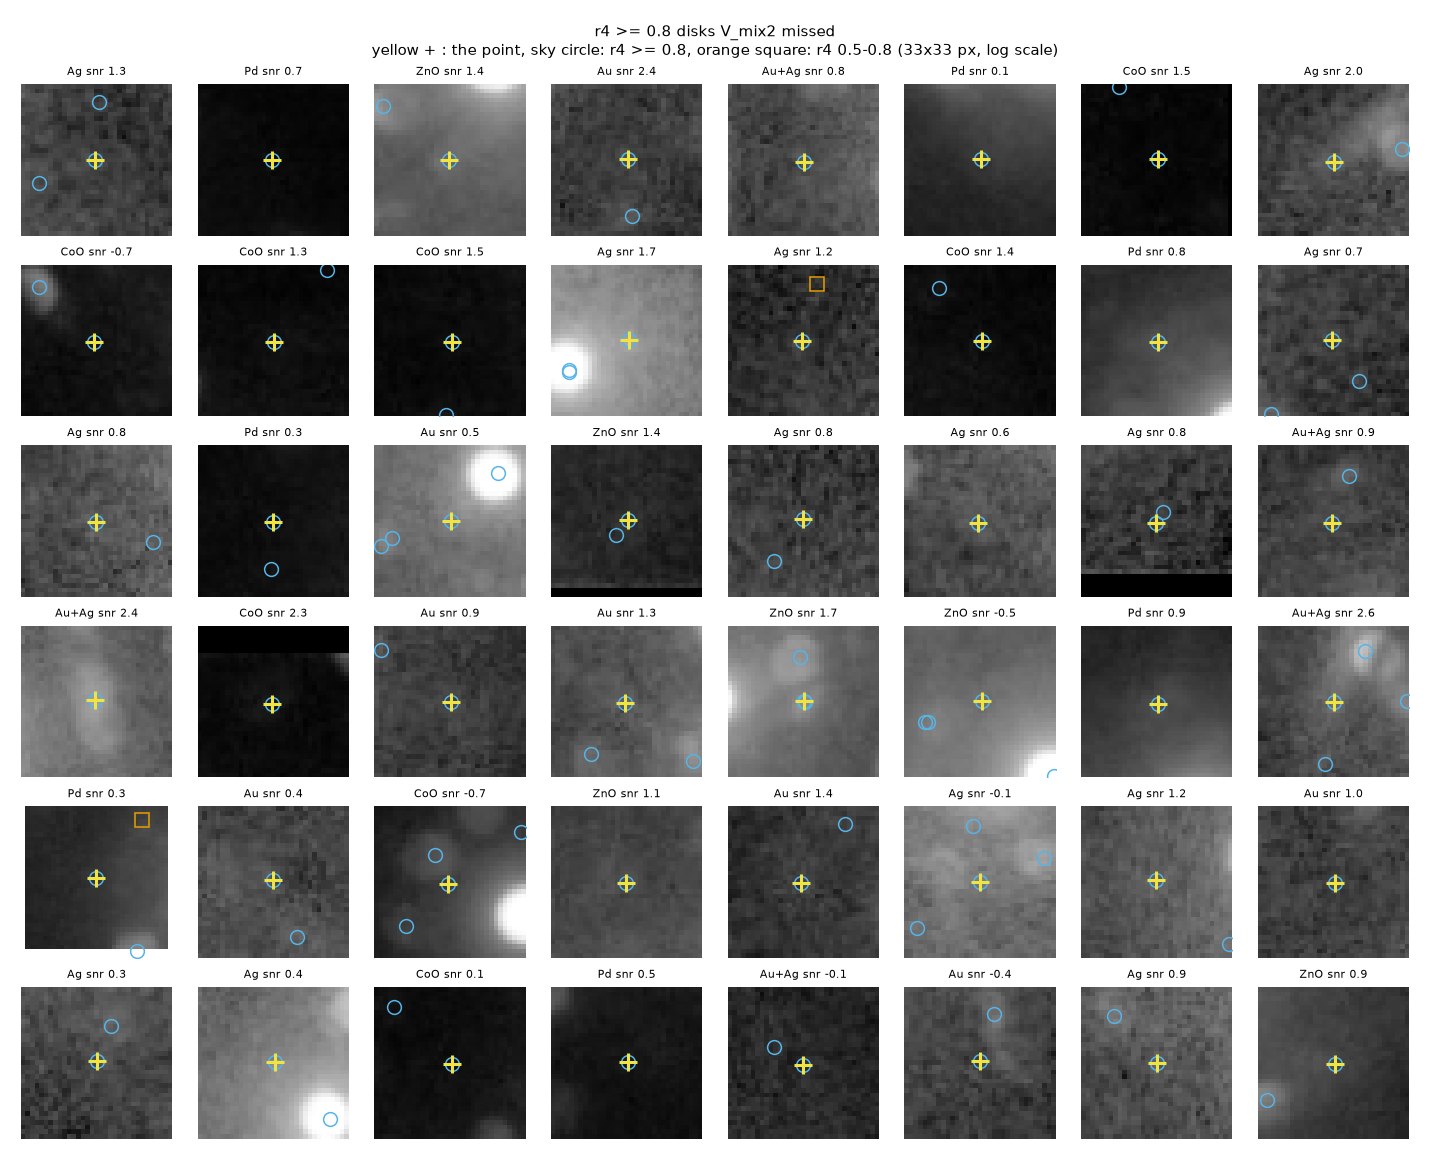

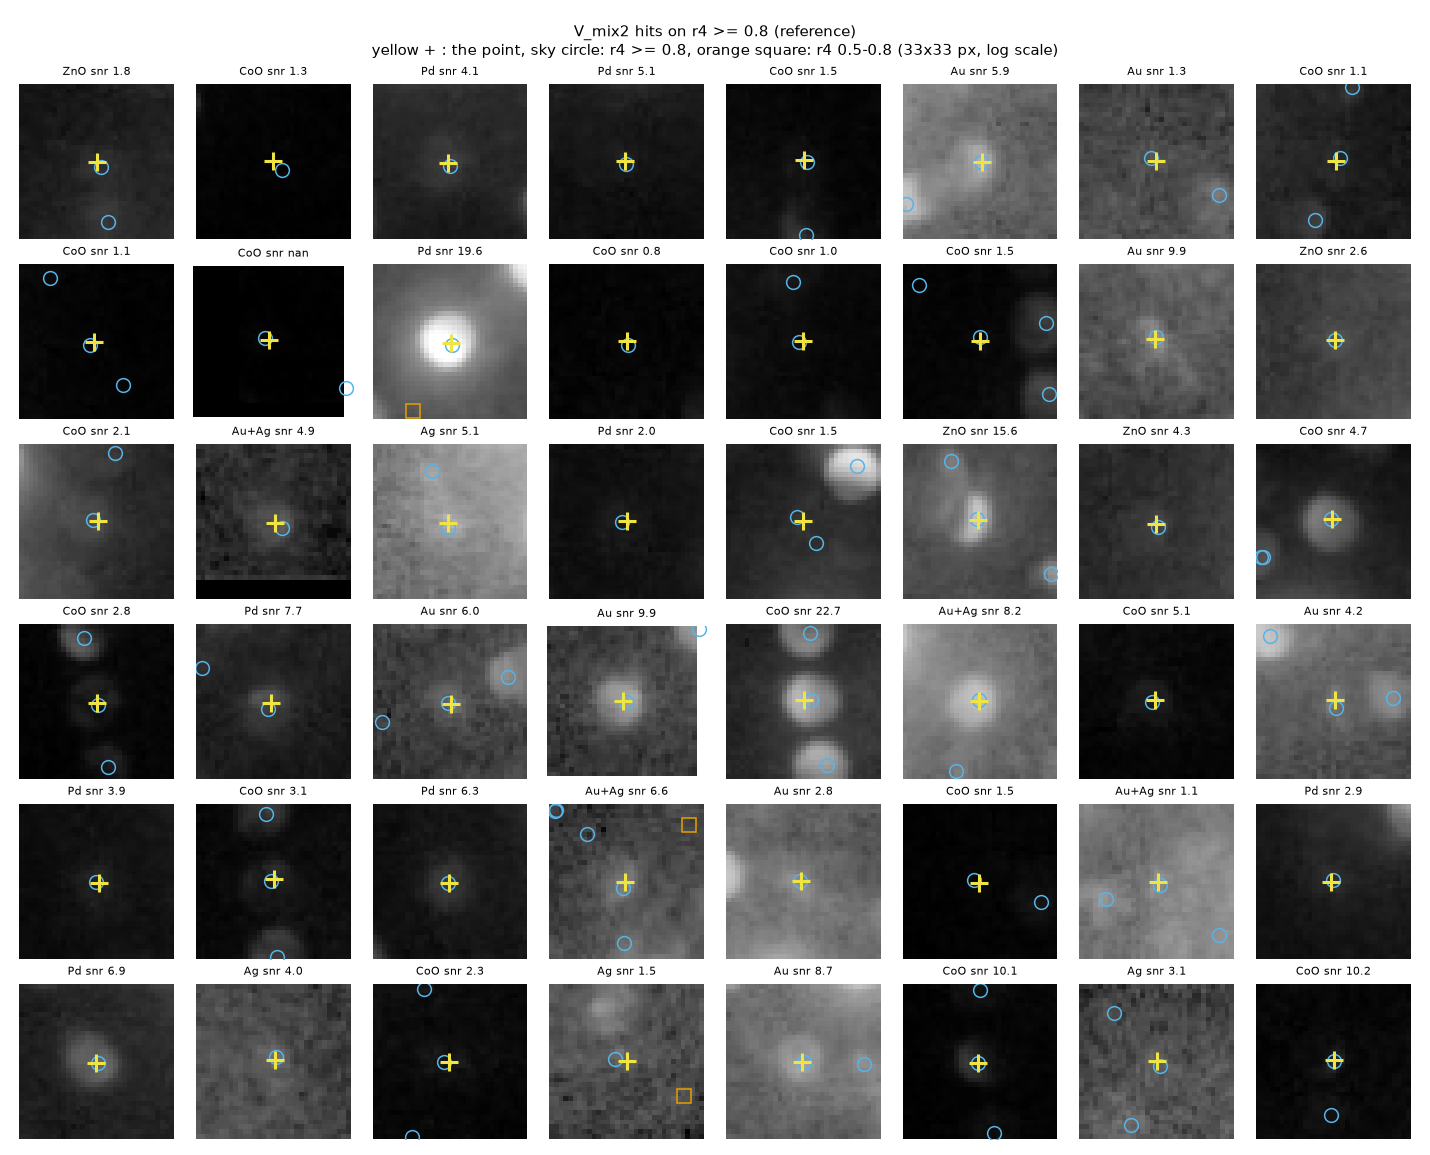

In [4]:
for name in ("gallery_no_label.png", "gallery_missed.png", "gallery_hits.png"):
    show(Image(str(LC / name)))

### Results of section 7

**The scoring fixes are small.**
- Removing the direct-beam label raises recall by about 1.5 points for every model; F1 goes up by about 0.008.
- Treating r4 0.5–0.8 disks as optional raises precision by about 2 points. Lenient F1: V_exp 0.721, V_mix2 0.716,
  V_mix 0.686. The ranking does not change.
- Scoring against all r4 disks (> 0.5) gives *lower* recall. The models do not find many of the weak r4 disks either.

**Detections without any r4 label (21 % of V_mix2's detections; CoO 12 %, other materials 21–25 %).**
- 11 % lie within 4 px of the pattern border, against 0.3 % of the r4 hits. These are edge artefacts and can be
  removed by ignoring a border strip.
- Their contrast is lower than that of r4 hits (median snr 2.1 vs 4.0), but nearly all (99 %) sit above the 95th
  percentile of background positions, partly because detections are local maxima.
- By eye, a minority are clear disks that r4 missed; many are faint bumps on flat noise, where it is hard to say if
  there is a disk.
- So precision is somewhat underestimated, but not by a large amount: these are mostly faint maybes, not obvious disks.

**r4 ≥ 0.8 disks V_mix2 missed (34 % of the labels).**
- Median contrast 0.8, about the 95th percentile of background; about half are indistinguishable from background noise
  in the single pattern. By eye, most crops show no visible disk.
- r4 probably places these from the lattice (the other disks of the pattern), not from the local signal. A model that
  looks at local intensity cannot find them, so **recall is limited mainly by the labels, not by the model**.

**What this means for the next steps.**
- Lowering the label confidence (step 3, r4 > 0.5) is unlikely to help: the extra labels are as faint as the missed
  ones.
- Cheap gains: ignore detections near the pattern border (removes about 2 % of V_mix2's detections, nearly all false).
- For a fair score, report recall on *visible* r4 disks (local contrast above background), as on the simulations.

## 8. Better checkpoint choice and better labels (V_mix3, V_mix4, V_mix5)

Three runs with V_mix2's settings (ft_V start, 20k experimental + 1650 × 12 simulated training patterns, lr 2e-4,
batch 16, at most 30 epochs). Each adds one change:

| run | change compared with V_mix2 |
|---|---|
| **V_mix3b** | best.pt = epoch with the **highest validation F1** (V_mix2: lowest validation loss); all 30 epochs |
| **V_mix4b** | V_mix3b + **score-weighted r4 labels**: every r4 disk (score > 0.5) is a training target, with peak height min(1, score / 0.8). Disks ≥ 0.8 count fully, a disk of score 0.5 counts 0.63 |
| **V_mix5b** | V_mix3b + **self-training**: V_mix2's detections with probability ≥ 0.55 that are > 3 px from every r4 disk (and away from the beam and the image edge) are added as labels. At 0.55 these have the same contrast as r4 hits (section 7: median snr 4.0) |

- **A first try with early stopping** (V_mix3, V_mix4, V_mix5: stop after 6 epochs without a better validation F1,
  at least 10 epochs) stopped too soon: at lr 2e-4 validation F1 swings by ±0.05 between epochs and rises only after
  the learning rate is halved (V_mix2: epoch 15). V_mix3 stopped after 10 epochs with its best at epoch 0. The "b" runs
  train all 30 epochs; the early-stopped runs are listed at the end of 8.2 for comparison.
- **Validation is the same for all runs:** the 3 experimental validation acquisitions with r4 ≥ 0.8 labels. Validation
  F1 is therefore experimental only; V_mix2's setup has no simulation validation set (`--sim-val-to-train`).
- **Testing is the same as in sections 3–4:** `eval_experimental.py`, results in `diffraction_runs/eval_exp2/`. The
  label scorings of section 7 are in `eval_exp2/labels_check/`.
- **Code:** `train_extras.py` (callbacks, weighted dataset, pseudo labels) and new options of `finetune_experimental.py`.
  The queue is `diffraction_runs/queue_step23/run.sh`.

In [2]:
EV2 = R / "eval_exp2"
NEW = ["V_exp", "V_mix2", "V_mix3b", "V_mix4b", "V_mix5b"]
EARLY = ["V_mix3", "V_mix4", "V_mix5"]           # first try, early stopped
for k in NEW[2:] + EARLY:
    RUNS[k] = R / f"ft_{k}"
STYLE.update({"V_mix3b": (SKY, "v"), "V_mix4b": (ORANGE, "s"), "V_mix5b": ("#000000", "X")})
DESC.update({"V_mix3b": "V_mix3b: V_mix2 + F1 checkpoint",
             "V_mix4b": "V_mix4b: V_mix3b + score-weighted r4 labels (> 0.5)",
             "V_mix5b": "V_mix5b: V_mix3b + self-training (V_mix2 pseudo labels)"})
NEW = [k for k in NEW if (RUNS[k] / "model/best.pt").exists()]
thr2 = json.loads((EV2 / "thresholds.json").read_text())
print("runs:", NEW)
print("thresholds (experimental / simulation):", {k: (thr2[k]["exp"], thr2[k]["sim"]) for k in NEW})
for k in NEW:
    pj = RUNS[k] / "pseudo_labels.json"
    if pj.exists():
        print(f"{k} pseudo labels:", json.loads(pj.read_text()))

runs: ['V_exp', 'V_mix2']
thresholds (experimental / simulation): {'V_exp': (0.396, 0.396), 'V_mix2': (0.47, 0.6)}


### 8.1 Training curves

Large marker: the kept checkpoint (V_mix2: lowest validation loss; V_mix3–5: highest validation F1). A line that ends
before epoch 29 was stopped early. V_mix2's line ends in epoch 26 because of the machine shutdown.

V_mix2: 27 epochs, kept epoch 16 (lowest val loss): val F1 0.728, val loss 0.361; max val F1 0.734 (epoch 23)


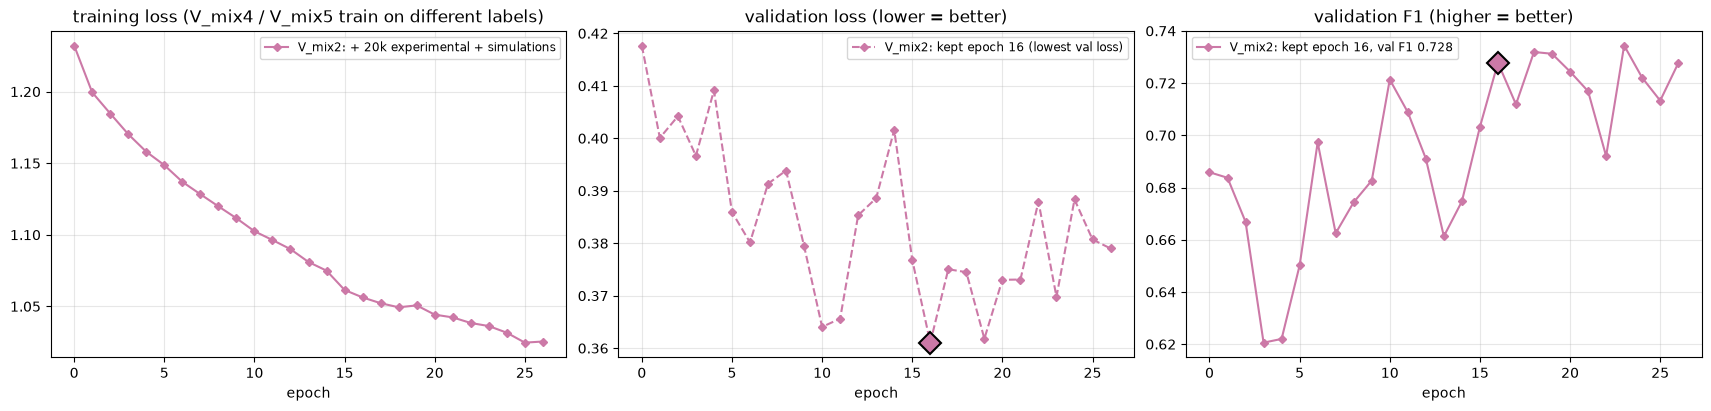

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4), constrained_layout=True)
for k in [k for k in NEW if k != "V_exp"]:
    col, mk = STYLE[k]
    m = pd.read_csv(sorted(RUNS[k].glob("logs/*/metrics.csv"))[-1])
    tr = m.dropna(subset=["train_loss"]).groupby("epoch").train_loss.last()
    v = m.dropna(subset=["val_loss"]).groupby("epoch")[["val_loss", "val_f1"]].last()
    sel = RUNS[k] / "model/selection.json"
    best = json.loads(sel.read_text())["best_epoch"] if sel.exists() else int(v.val_loss.idxmin())
    how = "highest val F1" if sel.exists() else "lowest val loss"
    kw = dict(color=col, marker=mk, ms=4, mec="black" if col == "#000000" else col)
    axs[0].plot(tr.index, tr, label=DESC[k], **kw)
    axs[1].plot(v.index, v.val_loss, ls="--", label=f"{k}: kept epoch {best} ({how})", **kw)
    axs[2].plot(v.index, v.val_f1, label=f"{k}: kept epoch {best}, val F1 {v.val_f1[best]:.3f}", **kw)
    for ax, y in ((axs[1], v.val_loss[best]), (axs[2], v.val_f1[best])):
        ax.plot(best, y, marker=mk, ms=11, color=col, mec="black", mew=1.5, ls="none")
    print(f"{k}: {len(v)} epochs, kept epoch {best} ({how}): val F1 {v.val_f1[best]:.3f}, "
          f"val loss {v.val_loss[best]:.3f}; max val F1 {v.val_f1.max():.3f} (epoch {int(v.val_f1.idxmax())})")
axs[0].set_title("training loss (V_mix4 / V_mix5 train on different labels)")
axs[1].set_title("validation loss (lower = better)")
axs[2].set_title("validation F1 (higher = better)")
for ax in axs:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8.5)
plt.show()

### 8.2 Experimental test

Same 6 test acquisitions × 500 patterns as section 3; each model at its own experimental threshold. The first table
uses the r4 ≥ 0.8 labels (as in section 3); the second shows the fairer scorings of section 7 (beam label removed;
r4 0.5–0.8 optional).

vs r4 >= 0.8 labels (as section 3):
             V_exp                  V_mix2              
         precision recall     f1 precision recall     f1
material                                                
Ag           0.669  0.491  0.567     0.729  0.389  0.507
Au           0.713  0.770  0.740     0.753  0.702  0.726
Au+Ag        0.663  0.668  0.666     0.726  0.598  0.656
CoO          0.782  0.778  0.780     0.869  0.708  0.780
Pd           0.629  0.797  0.703     0.754  0.720  0.737
ZnO          0.615  0.806  0.698     0.710  0.755  0.732
all          0.688  0.717  0.702     0.767  0.643  0.700

all test materials, by scoring (section 7):
        threshold                         precision                         recall                             f1                        
scoring    all_r4 current lenient no_beam    all_r4 current lenient no_beam all_r4 current lenient no_beam all_r4 current lenient no_beam
model                                                                    

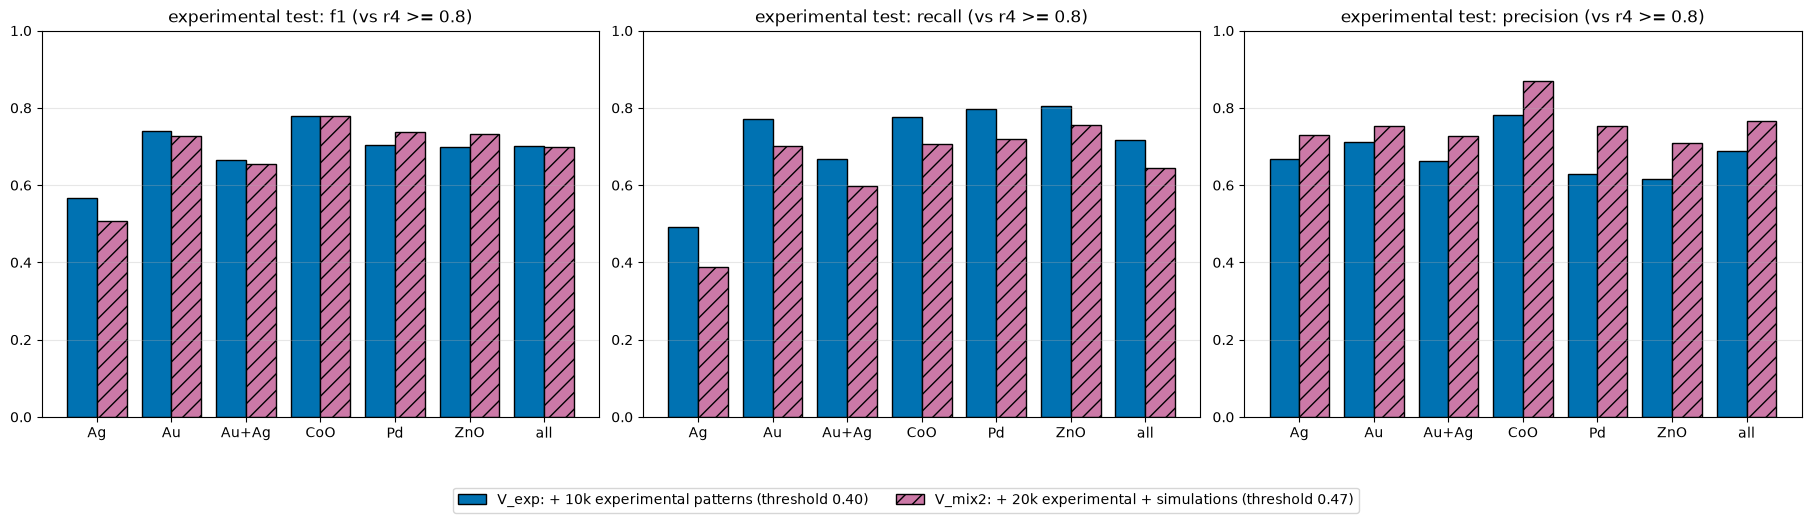

In [4]:
exp2 = pd.read_csv(EV2 / "exp_test.csv").set_index(["model", "material"])
e = pd.concat({k: exp2.loc[k] for k in NEW}, axis=1)
print("vs r4 >= 0.8 labels (as section 3):")
print(e.loc[:, (slice(None), ["precision", "recall", "f1"])].round(3).to_string())
lc2 = EV2 / "labels_check/scores.csv"
if lc2.exists():
    sc2 = pd.read_csv(lc2).set_index(["model", "scoring", "material"]).xs("all", level="material")
    print("\nall test materials, by scoring (section 7):")
    print(sc2.loc[[k for k in NEW if k in sc2.index.get_level_values(0)]][["threshold", "precision", "recall", "f1"]]
          .unstack("scoring").round(3).to_string())
early = [k for k in EARLY if k in exp2.index.get_level_values(0)]
if early:
    print("\nfirst try, early stopped (vs r4 >= 0.8, all test materials):")
    print(pd.concat({k: exp2.loc[(k, "all")] for k in early}, axis=1).T[["precision", "recall", "f1"]].round(3)
          .assign(threshold=[thr2[k]["exp"] for k in early]).to_string())

mats = [m for m in e.index if m != "all"] + ["all"]
fig, axs = plt.subplots(1, 3, figsize=(18, 4.4), constrained_layout=True)
w = 0.8 / len(NEW)
hatch = ["", "//", "..", "xx", "\\\\"]
for ax, metric in zip(axs, ("f1", "recall", "precision")):
    x = np.arange(len(mats))
    for i, k in enumerate(NEW):
        col, _ = STYLE[k]
        ax.bar(x + (i - (len(NEW) - 1) / 2) * w, e.loc[mats, (k, metric)].values, w, color=col,
               edgecolor="white" if col == "#000000" else "black", hatch=hatch[i],
               label=f"{DESC[k]} (threshold {thr2[k]['exp']:.2f})")
    ax.set_xticks(x, mats)
    ax.set(ylim=(0, 1), title=f"experimental test: {metric} (vs r4 >= 0.8)")
    ax.grid(alpha=0.3, axis="y")
fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.17), fontsize=10)
plt.show()

**Same threshold rule for every model.** The thresholds above come from different rules: spotiflow's
`optimize_threshold` (random 128-px crops of the validation patterns; V_exp, V_mix, V_mix3–5) or whole validation
patterns (V_mix2). The crop rule gives lower thresholds (0.31–0.40) than the whole-pattern rule (0.44–0.48). Here
every model uses the threshold with the best F1 on the **whole validation patterns** (grid step 0.02, from
`exp_sweep.csv`), and the test scores are read at that threshold.

test_f1_own: at the model's own threshold (nearest grid point); test_*: at the whole-pattern val threshold


,own_threshold,test_f1_own,whole_val_threshold,val_f1,test_precision,test_recall,test_f1
model,,,,,,,
V_exp,0.396,0.704,0.46,0.733,0.777,0.651,0.709
V_mix,0.308,0.664,0.44,0.714,0.792,0.621,0.696
V_mix2,0.470,0.700,0.48,0.729,0.783,0.629,0.698
V_mix3,0.372,0.648,0.46,0.686,0.758,0.595,0.667
V_mix4,0.348,0.635,0.48,0.720,0.772,0.646,0.703
V_mix5,0.372,0.666,0.46,0.721,0.733,0.647,0.687


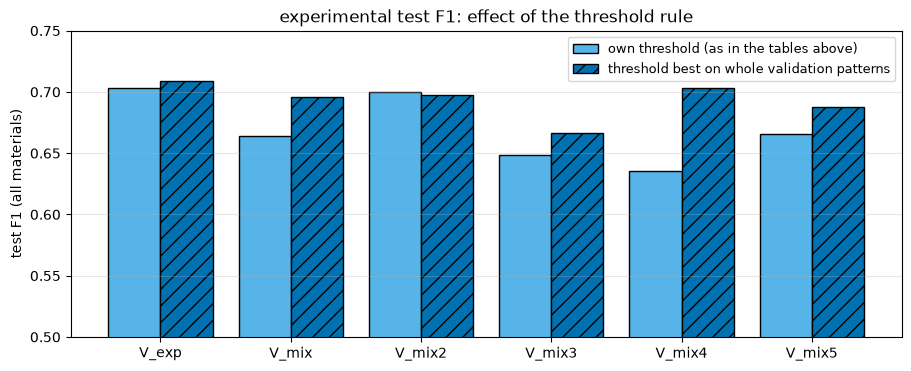

In [5]:
sw = pd.read_csv(EV2 / "exp_sweep.csv")
rows = []
for k, g in sw.groupby("model"):
    v = g[g.split == "val"]
    t = v.loc[v.f1.idxmax(), "threshold"]
    te = g[(g.split == "test") & (g.threshold == t)].iloc[0]
    own = g[(g.split == "test")].iloc[(g[g.split == "test"].threshold - thr2[k]["exp"]).abs().argmin()]
    rows.append(dict(model=k, own_threshold=thr2[k]["exp"], test_f1_own=own.f1, whole_val_threshold=t,
                     val_f1=v.f1.max(), test_precision=te.precision, test_recall=te.recall, test_f1=te.f1))
fair = pd.DataFrame(rows).set_index("model").drop(index="V", errors="ignore")
print("test_f1_own: at the model's own threshold (nearest grid point); test_*: at the whole-pattern val threshold")
display(fair.round(3))
fig, ax = plt.subplots(figsize=(9, 3.6), constrained_layout=True)
x = np.arange(len(fair))
ax.bar(x - 0.2, fair.test_f1_own, 0.4, color=SKY, edgecolor="black", label="own threshold (as in the tables above)")
ax.bar(x + 0.2, fair.test_f1, 0.4, color=BLUE, edgecolor="black", hatch="//",
       label="threshold best on whole validation patterns")
ax.set_xticks(x, fair.index)
ax.set(ylim=(0.5, 0.75), ylabel="test F1 (all materials)", title="experimental test F1: effect of the threshold rule")
ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=9)
plt.show()

### 8.3 Simulation test

Same 45 simulation test patterns as section 4 (BW, Co₃(O₂F)₂, SiO₂ at 1, 2 and 4 mrad). `own` = the experimental
threshold, `sim` = the separate simulation threshold (tune_sim_threshold rule).

angle                           1.0    2.0    4.0
V_exp own (0.40)  recall_vis  0.738  0.419  0.063
                  precision   0.571  0.472  0.097
V_mix2 own (0.47) recall_vis  0.861  0.761  0.592
                  precision   0.917  0.931  0.806
V_mix2 sim (0.60) recall_vis  0.531  0.408  0.410
                  precision   0.972  0.962  0.952


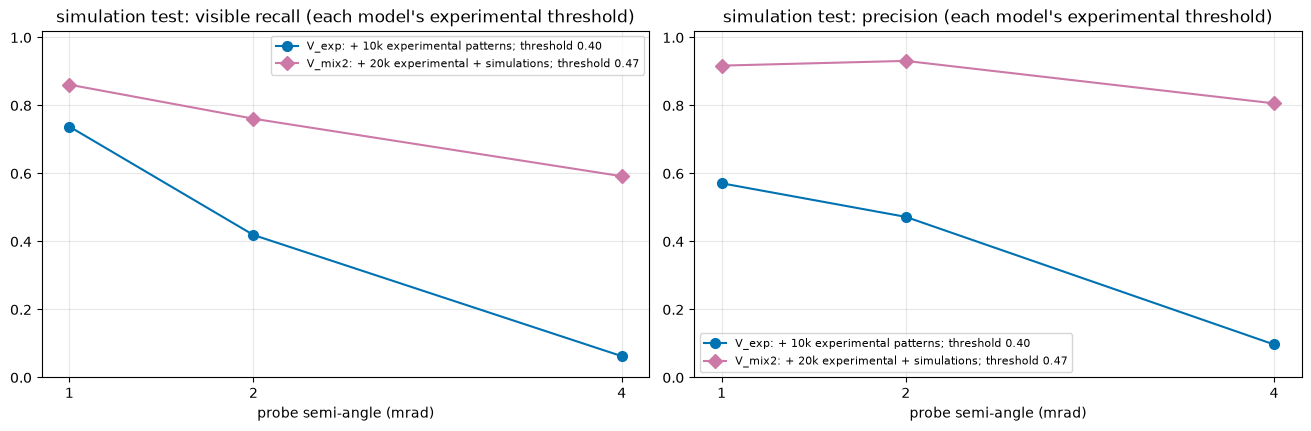

In [6]:
sim2 = pd.read_csv(EV2 / "sim_test.csv").set_index(["model", "rule", "angle"])
cols = {}
for k in NEW:
    for rule in ("own", "sim"):
        if rule == "sim" and thr2[k]["sim"] == thr2[k]["exp"]:
            continue
        cols[f"{k} {rule} ({thr2[k]['exp' if rule == 'own' else 'sim']:.2f})"] = sim2.loc[(k, rule)]
s2 = pd.concat(cols, axis=1)
print(s2.loc[:, (slice(None), ["recall_vis", "precision"])].round(3).T.to_string())

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
for k in NEW:
    col, mk = STYLE[k]
    s = sim2.loc[(k, "own")]
    kw = dict(color=col, marker=mk, ms=7, mec="black" if col == "#000000" else col)
    axs[0].plot(s.index, s.recall_vis, label=f"{DESC[k]}; threshold {thr2[k]['exp']:.2f}", **kw)
    axs[1].plot(s.index, s.precision, label=f"{DESC[k]}; threshold {thr2[k]['exp']:.2f}", **kw)
for ax, t in zip(axs, ("visible recall", "precision")):
    ax.set(xlabel="probe semi-angle (mrad)", xticks=[1, 2, 4], ylim=(0, 1.02),
           title=f"simulation test: {t} (each model's experimental threshold)")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

### Results of section 8

*(written after the runs finished)*